# Notebook 03 — Análise estatística: as features são normais? O log ajuda?

**O que buscamos aqui:** os Notebooks 01 e 02 mostraram *o que muda* entre o normal e a anomalia. Agora fazemos uma pergunta de outro tipo: **qual é o formato das distribuições das features?** Isso decide como tratar os dados antes do K-Means (Notebook 04) e da classificação (Notebook 05). Quatro perguntas:

1. As 109 features seguem uma **distribuição normal** (o "sino" simétrico)? Quais sim, quais não?
2. As que não seguem são **muito tortas** ou só um pouco? (Teste e assimetria podem discordar.)
3. Como o formato é visto **a olho**, em histogramas e QQ-plots?
4. A **transformação logarítmica** deixa as features mais normais? Em quais?

| Passo | O que fazemos | O que buscamos |
| --- | --- | --- |
| 1 | Configurar parâmetros | Escolher as condições e os limites estatísticos |
| 2 | Carregar as bases | As mesmas bases dos Notebooks 01 e 02 |
| 3 | Cortar em janelas e calcular as 109 features | A mesma tabela do Notebook 02 |
| 4 | Explicar as escolhas estatísticas | Entender o que será testado e por quê |
| 5 | Shapiro-Wilk com correção para muitos testes | Quantas features parecem normais |
| 6 | Assimetria, histogramas e QQ-plots | O quanto e como elas se afastam da normal |
| 7 | Autocorrelação entre janelas | O quanto os p-valores merecem confiança |
| 8 | Transformação logarítmica | O log aproximou as features da normal? |
| 9 | Features que não aceitam log (curtose) | Alternativa para elas |
| Resumo | Tabela e decisões | O que levar para o Notebook 04 |

## Sobre os dados desta versão (dados novos)

Esta é a versão do Notebook 03 para os **dados novos** (pasta `NOVOS_DADOS`): normal, fita 1g, papel e porca frouxa nas três velocidades, com a oscilação ligada. As três falhas entram automaticamente como condições comparadas.

Duas diferenças em relação aos dados antigos mudam a leitura deste notebook:

* **Aquecimento:** cada gravação começou com o motor frio, e a rotação **sobe ao longo da gravação** nas Vel 1 e 2 (Notebooks 01 e 02). Uma feature que muda devagar com o tempo não forma um sino: ela se espalha por uma faixa larga. Isso afeta os testes de normalidade (Passo 5) e, principalmente, a autocorrelação (Passo 7).
* **Corte do começo e do fim:** os primeiros e os últimos 5 s de cada base são descartados (falhas de leitura do sensor ao ligar a gravação), como nos Notebooks 01 e 02.


## Como usar

1. Use a mesma pasta de bases dos Notebooks 01 e 02 (`<condicao>_vel_<N>.csv`).
2. No Passo 1, confira `CONDICOES_REFERENCIA`. Condições novas na pasta (como `desbalanceamento_1g`) entram **sozinhas** em todos os testes e gráficos.
3. Rode as células em ordem. **Em cada passo, leia primeiro o texto e depois os resultados**: a parte estatística é fácil de errar quando se olha só o número.

## Glossário rápido (volte aqui sempre que travar)

* **Distribuição normal:** o "sino". A maioria dos valores fica perto da média, e os extremos são raros e simétricos dos dois lados.
* **Teste de normalidade (Shapiro-Wilk):** parte da hipótese de que os dados **são** normais e pergunta: *"se fossem mesmo normais, seria muito raro eu ver um formato tão diferente do sino?"*
* **p-valor:** a resposta dessa pergunta. **p pequeno (abaixo de 0,05)** quer dizer "seria muito raro": rejeitamos a normalidade. **p grande** quer dizer "não há evidência contra": a feature *pode* ser normal (isso **não prova** que seja).
* **W:** a nota do teste, de 0 a 1. **1 = sino perfeito.** Quanto menor, mais distante.
* **Assimetria (skewness):** 0 = simétrica. **Positiva:** cauda comprida para a direita (alguns valores muito altos). **Negativa:** cauda para a esquerda.
* **QQ-plot:** compara os seus dados com uma normal ideal. **Pontos sobre a reta = normal.** Pontos curvos ou espalhados = fora da normal.
* **Correção para muitos testes (BH):** quando se faz 109 testes de uma vez, alguns dão p < 0,05 só por sorte. A correção ajusta isso (Passo 4). O p ajustado se chama **q**.
* **Log:** troca cada valor pelo seu logaritmo. "Espreme" valores muito grandes e deixa distribuições com cauda comprida mais simétricas.

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte.

## Passo 1 — Configuração

**O que buscamos:** concentrar num só lugar tudo o que muda de um experimento para outro. As três escolhas **estatísticas** estão no bloco "ESTATÍSTICA" e cada uma é explicada no Passo 4.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import kurtosis, shapiro, skew, norm, yeojohnson
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})

In [2]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS (a mesma pasta dos Notebooks 01 e 02)
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\NOVOS_DADOS")
BUSCAR_EM_SUBPASTAS = True        # True = lê também os CSVs dentro das subpastas (NORMAL, ANOMALIA)
DESCARTAR_INICIO_S = 5            # segundos descartados no começo de cada base (Notebook 01, Passo 4.1)
DESCARTAR_FIM_S = 5               # segundos descartados no fim de cada base

# ----------------------------------------------------------------------
# QUEM É REFERÊNCIA E QUEM É COMPARADO
# ----------------------------------------------------------------------
CONDICOES_REFERENCIA = ["ventilador_normal"]   # use o prefixo do nome do arquivo; várias rodadas entram juntas
CONDICOES_COMPARADAS = None                    # None = todas as outras condições da pasta

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000
EIXOS = ["x", "y", "z"]
UNIDADE = "m/s²"

# ----------------------------------------------------------------------
# JANELAS E FEATURES (a mesma receita do Notebook 02: 109 features)
# ----------------------------------------------------------------------
JANELA_S = 5                      # janela de 5 s, sem sobreposição
FAIXA_FFT_HZ = (5, 305)           # faixas de 10 Hz de 5 a 305 Hz
LARGURA_FAIXA_HZ = 10
FAIXA_BUSCA_1X_HZ = (8, 30)       # faixa onde procuramos o pico de rotação
DESVIO_MAX_1X_HZ = 2.0            # o 1X só pode ficar a até esta distância da rotação típica da base
N_HARMONICAS = 3                  # mede 1X, 2X e 3X
TOLERANCIA_HARMONICA_HZ = 0.6     # a amplitude de kX é o maior pico a até esta distância de k vezes o 1X

# ----------------------------------------------------------------------
# ESTATÍSTICA (explicadas no Passo 4)
# ----------------------------------------------------------------------
ALFA = 0.05                       # nível de significância: p (ou q) abaixo disto rejeita a normalidade
LIMITE_ASSIMETRIA = 1.0           # |assimetria| acima disto = distribuição claramente torta
MIN_JANELAS = 20                  # com menos janelas que isto o teste não é feito
LIMITE_Z_ROBUSTO = 8              # uma feature é "extrema" numa janela se passa disto em desvios robustos (MAD)
MIN_FEATURES_ATIPICAS = 10        # uma janela é "atípica" se tem pelo menos este número de features extremas

# ----------------------------------------------------------------------
# CICLO LENTO DA VIBRAÇÃO (Passo 7.2)
# ----------------------------------------------------------------------
EIXO_MODULACAO = "z"              # eixo cuja intensidade é acompanhada ao longo do tempo
BLOCO_MODULACAO_S = 0.25          # a intensidade (desvio padrão) é medida a cada bloco deste tamanho
FAIXA_PERIODO_MODULACAO_S = (3, 30)   # procuramos ciclos de 3 s a 30 s

# ----------------------------------------------------------------------
# TENDÊNCIA LENTA (AQUECIMENTO) — Passo 7.3
# ----------------------------------------------------------------------
JANELAS_TENDENCIA = 13            # a tendência é a mediana móvel de 13 janelas (65 s), larga demais para seguir o ciclo da oscilação
BASE_EXEMPLO_TENDENCIA = "ventilador_normal_vel_1"   # base usada no gráfico de exemplo
FEATURE_EXEMPLO_TENDENCIA = "f1x_hz"                # feature usada no gráfico de exemplo

# ----------------------------------------------------------------------
# GRÁFICOS
# ----------------------------------------------------------------------
VELOCIDADE_EXEMPLO = 2            # velocidade usada nos histogramas e QQ-plots
FEATURES_EXEMPLO = ["std_z", "pico_z", "fft_035_045Hz_z", "amp_1x_z", "kurt_z"]   # features mostradas nos gráficos de exemplo

# ----------------------------------------------------------------------
# APARÊNCIA
# ----------------------------------------------------------------------
COR_REFERENCIA = "dodgerblue"
COR_COMPARADA = "crimson"
CORES_TIPO = {"tempo": "tab:green", "FFT": "tab:purple", "rotação": "tab:orange"}
NOMES_EIXOS = {"x": "Eixo X (lateral)", "y": "Eixo Y (frontal)", "z": "Eixo Z (vertical)"}

## Passo 2 — Carregar as bases

**O que buscamos:** ler a pasta e conferir o que existe. **O código desta parte é o mesmo do Notebook 02**, copiado sem alterações, para garantir que as features sejam idênticas.

A tabela mostra quantas bases e quantos segundos existem por condição e velocidade. **Cada 5 s vira uma janela, e cada janela é uma "observação" nos testes estatísticos.** Poucos segundos significam poucas janelas e testes menos confiáveis.

In [3]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)$")


def ler_rotulo_do_nome(nome_base):
    """Separa o nome 'fita_1g_vel_2' em condição ('fita_1g') e velocidade (2)."""
    encontrado = PADRAO_NOME.match(nome_base)
    if encontrado is None:
        raise ValueError(
            f"Nome fora do padrão: '{nome_base}'. Use <condicao>_vel_<N>, por exemplo 'fita_1g_vel_2'."
        )
    return encontrado["condicao"], int(encontrado["velocidade"])


def carregar_base(caminho):
    """Lê um CSV e devolve só as colunas x, y e z como números decimais."""
    df = pd.read_csv(caminho)
    faltando = [eixo for eixo in EIXOS if eixo not in df.columns]
    if faltando:
        raise ValueError(f"{Path(caminho).name}: faltam as colunas {faltando}. Colunas encontradas: {list(df.columns)}")
    return df[EIXOS].astype(float)


def carregar_todas_as_bases(pasta):
    """Lê todos os CSVs da pasta. Devolve (bases, catalogo), ordenados por condição e velocidade."""
    arquivos = sorted(Path(pasta).rglob("*.csv") if BUSCAR_EM_SUBPASTAS else Path(pasta).glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum CSV em '{pasta}'. Confira PASTA_BASES.")
    bases, linhas = {}, []
    for arquivo in arquivos:
        nome = arquivo.stem
        condicao, velocidade = ler_rotulo_do_nome(nome)
        bases[nome] = carregar_base(arquivo)
        linhas.append({
            "base": nome,
            "condicao": condicao,
            "velocidade": velocidade,
            "linhas": len(bases[nome]),
            "duracao_s": len(bases[nome]) / TAXA_AMOSTRAGEM_HZ,
        })
    catalogo = pd.DataFrame(linhas).sort_values(["condicao", "velocidade"]).set_index("base")
    bases = {nome: bases[nome] for nome in catalogo.index}
    return bases, catalogo



def aparar_bases(bases, catalogo, inicio_s=DESCARTAR_INICIO_S, fim_s=DESCARTAR_FIM_S):
    """Descarta inicio_s segundos do começo e fim_s do fim de cada base (o mesmo corte do Notebook 01)."""
    inicio, fim = int(inicio_s * TAXA_AMOSTRAGEM_HZ), int(fim_s * TAXA_AMOSTRAGEM_HZ)
    aparadas = {nome: df.iloc[inicio: len(df) - fim].reset_index(drop=True) for nome, df in bases.items()}
    catalogo = catalogo.copy()
    catalogo["linhas"] = [len(aparadas[nome]) for nome in catalogo.index]
    catalogo["duracao_s"] = catalogo["linhas"] / TAXA_AMOSTRAGEM_HZ
    return aparadas, catalogo


def definir_comparacoes(catalogo, condicoes_referencia, condicoes_comparadas=None):
    """Confere a referência e devolve a lista de condições que serão comparadas com ela."""
    existentes = sorted(catalogo["condicao"].unique())
    faltando = [c for c in condicoes_referencia if c not in existentes]
    if faltando:
        raise ValueError(f"Condição de referência não encontrada: {faltando}. Condições na pasta: {existentes}")
    if condicoes_comparadas is None:
        condicoes_comparadas = [c for c in existentes if c not in condicoes_referencia]
    faltando = [c for c in condicoes_comparadas if c not in existentes]
    if faltando:
        raise ValueError(f"Condição comparada não encontrada: {faltando}. Condições na pasta: {existentes}")
    if not condicoes_comparadas:
        raise ValueError(
            "Não há nenhuma condição para comparar com a referência. "
            "Coloque na pasta as bases da anomalia (por exemplo fita_1g_vel_1.csv)."
        )
    return list(condicoes_comparadas)


def resumir_catalogo(catalogo):
    """Número de bases e total de segundos por condição e velocidade."""
    return catalogo.groupby(["condicao", "velocidade"]).agg(bases=("linhas", "size"), duracao_s=("duracao_s", "sum"))


def avisar_velocidades_sem_referencia(catalogo, condicoes_referencia, condicoes_comparadas):
    """Avisa quando uma condição comparada tem uma velocidade que a referência não tem."""
    velocidades_ref = set(catalogo.loc[catalogo["condicao"].isin(condicoes_referencia), "velocidade"])
    for condicao in condicoes_comparadas:
        velocidades = set(catalogo.loc[catalogo["condicao"] == condicao, "velocidade"])
        sem_ref = sorted(velocidades - velocidades_ref)
        if sem_ref:
            print(f"ATENÇÃO: '{condicao}' tem as velocidades {sem_ref}, que a referência não tem. Elas ficarão sem comparação.")

In [4]:
bases, catalogo = carregar_todas_as_bases(PASTA_BASES)
bases, catalogo = aparar_bases(bases, catalogo)
condicoes_comparadas = definir_comparacoes(catalogo, CONDICOES_REFERENCIA, CONDICOES_COMPARADAS)
velocidades = sorted(catalogo["velocidade"].unique())

print(f"Referência: {CONDICOES_REFERENCIA}")
print(f"Comparadas: {condicoes_comparadas}")
avisar_velocidades_sem_referencia(catalogo, CONDICOES_REFERENCIA, condicoes_comparadas)
display(resumir_catalogo(catalogo))

Referência: ['ventilador_normal']
Comparadas: ['fita_1g', 'papel', 'porca_frouxa']


bases  duracao_s
condicao          velocidade                  
fita_1g           1               1    619.500
                  2               1    647.000
                  3               1    633.500
papel             1               1    629.000
                  2               1    633.000
                  3               1    642.500
porca_frouxa      1               1    638.000
                  2               1    638.492
                  3               1    640.500
ventilador_normal 1               1    636.000
                  2               1    647.500
                  3               1    623.500

## Passo 3 — Cortar em janelas e calcular as 109 features

**O que buscamos:** a mesma tabela de features do Notebook 02, para que tudo aqui seja comparável com o que já foi visto.

* **9 de tempo:** desvio padrão (`std`), curtose (`kurt`) e pico (`pico`), por eixo.
* **90 de FFT:** o máximo de cada faixa de 10 Hz (5 a 305 Hz), por eixo.
* **9 de rotação:** a amplitude em 1X, 2X e 3X, por eixo (`amp_1x_x` etc.).
* **1 de rotação estimada:** `f1x_hz`.

Total: 9 + 90 + 9 + 1 = **109 features**.

In [5]:
def faixas_de_frequencia():
    """Lista de faixas (início, fim) em Hz, como (5, 15), (15, 25), ..., (295, 305)."""
    limites = np.arange(FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1] + LARGURA_FAIXA_HZ, LARGURA_FAIXA_HZ)
    return [(int(inicio), int(fim)) for inicio, fim in zip(limites[:-1], limites[1:])]


def colunas_fft_do_eixo(eixo):
    """Nomes das colunas de FFT de um eixo, na ordem das faixas."""
    return [f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}" for inicio, fim in faixas_de_frequencia()]


def calcular_features_e_espectros(df, janela_s=JANELA_S):
    """Corta a base em janelas sem sobreposição e calcula as features de cada janela.

    A última janela incompleta é descartada. Devolve (features, frequencias, espectros):
      features: uma linha por janela, com as colunas std_x, kurt_x, pico_x, ..., fft_005_015Hz_x, ...
      frequencias: eixo de frequências (Hz), de FAIXA_FFT_HZ[0] até FAIXA_FFT_HZ[1]
      espectros: magnitude de cada janela, no formato (janela, frequência, eixo)
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    dados = df[EIXOS].to_numpy()[: n_janelas * tamanho]
    janelas = dados.reshape(n_janelas, tamanho, len(EIXOS))        # (janela, amostra, eixo)
    janelas = janelas - janelas.mean(axis=1, keepdims=True)         # remove o componente DC de cada janela

    colunas = {}
    std = janelas.std(axis=1, ddof=1)
    curtose = kurtosis(janelas, axis=1, fisher=True)
    pico = np.abs(janelas).max(axis=1)
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"] = std[:, k]
        colunas[f"kurt_{eixo}"] = curtose[:, k]
        colunas[f"pico_{eixo}"] = pico[:, k]

    # FFT com janela de Hanning; o fator 4/N compensa a energia que a janela remove
    janela_hanning = np.hanning(tamanho)[None, :, None]
    magnitude = np.abs(np.fft.rfft(janelas * janela_hanning, axis=1)) * (4.0 / tamanho)
    frequencias = np.fft.rfftfreq(tamanho, d=1.0 / TAXA_AMOSTRAGEM_HZ)

    for inicio, fim in faixas_de_frequencia():
        na_faixa = (frequencias >= inicio) & (frequencias < fim)
        maximo_da_faixa = magnitude[:, na_faixa, :].max(axis=1)     # (janela, eixo)
        for k, eixo in enumerate(EIXOS):
            colunas[f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}"] = maximo_da_faixa[:, k]

    no_intervalo = (frequencias >= FAIXA_FFT_HZ[0]) & (frequencias < FAIXA_FFT_HZ[1])
    return pd.DataFrame(colunas), frequencias[no_intervalo], magnitude[:, no_intervalo, :]


def analisar_todas_as_bases(bases, catalogo, janela_s=JANELA_S):
    """Calcula as features de todas as bases e junta numa só tabela.

    Devolve (features, frequencias, espectros_por_base). A tabela tem as colunas
    base, condicao, velocidade e janela (posição da janela dentro da base), mais as 99 features.
    """
    tabelas, espectros_por_base, frequencias = [], {}, None
    for nome, df in bases.items():
        features, frequencias, espectros = calcular_features_e_espectros(df, janela_s)
        features.insert(0, "janela", np.arange(len(features)))
        features.insert(0, "velocidade", catalogo.loc[nome, "velocidade"])
        features.insert(0, "condicao", catalogo.loc[nome, "condicao"])
        features.insert(0, "base", nome)
        tabelas.append(features)
        espectros_por_base[nome] = espectros
    return pd.concat(tabelas, ignore_index=True), frequencias, espectros_por_base

In [6]:
features, frequencias, espectros_por_base = analisar_todas_as_bases(bases, catalogo)

COLUNAS_TEMPO = [f"{tipo}_{eixo}" for tipo in ("std", "kurt", "pico") for eixo in EIXOS]
COLUNAS_FFT = [coluna for eixo in EIXOS for coluna in colunas_fft_do_eixo(eixo)]

print(f"Features por janela: {len(COLUNAS_TEMPO)} de tempo + {len(COLUNAS_FFT)} de FFT = {len(COLUNAS_TEMPO) + len(COLUNAS_FFT)}")
print(f"Janelas de {JANELA_S} s por condição e velocidade:")
display(features.groupby(["condicao", "velocidade"]).size().unstack().rename_axis(columns="Vel"))

Features por janela: 9 de tempo + 90 de FFT = 99
Janelas de 5 s por condição e velocidade:


Vel,1,2,3
condicao,,,
fita_1g,123,129,126
papel,125,126,128
porca_frouxa,127,127,128
ventilador_normal,127,129,124


In [7]:
def estimar_f1x(frequencias, espectros):
    """Rotação 1X de cada janela, em duas passadas.

    1ª passada: pico da soma dos três eixos dentro de FAIXA_BUSCA_1X_HZ, janela por janela.
    A mediana dessas janelas é a rotação típica da base.
    2ª passada: repete a busca, mas só a até DESVIO_MAX_1X_HZ da rotação típica. Isso evita que, numa
    anomalia forte, o pico do 2X ou de outra frequência seja confundido com o 1X.
    """
    soma_dos_eixos = espectros.sum(axis=2)                                         # (janela, frequência)
    na_faixa = (frequencias >= FAIXA_BUSCA_1X_HZ[0]) & (frequencias <= FAIXA_BUSCA_1X_HZ[1])
    primeira = frequencias[na_faixa][soma_dos_eixos[:, na_faixa].argmax(axis=1)]
    tipica = np.median(primeira)
    perto = na_faixa & (np.abs(frequencias - tipica) <= DESVIO_MAX_1X_HZ)
    return frequencias[perto][soma_dos_eixos[:, perto].argmax(axis=1)]


def medir_amplitudes_harmonicas(frequencias, espectros, f1x, n_harmonicas, tolerancia_hz):
    """Amplitude de 1X, 2X, ... em cada janela e eixo: o maior pico a até tolerancia_hz de k vezes o 1X."""
    colunas = {}
    for k in range(1, n_harmonicas + 1):
        alvo = k * f1x                                                           # (janela,)
        perto = np.abs(frequencias[None, :] - alvo[:, None]) <= tolerancia_hz     # (janela, frequência)
        for j, eixo in enumerate(EIXOS):
            colunas[f"amp_{k}x_{eixo}"] = np.where(perto, espectros[:, :, j], 0.0).max(axis=1)
    return pd.DataFrame(colunas)


def adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base):
    """Acrescenta à tabela a rotação (f1x_hz) e as amplitudes amp_1x_x, amp_2x_x, ... de cada janela."""
    features = features.drop(columns=[c for c in features.columns if c.startswith("amp_") or c == "f1x_hz"])
    partes = []
    for nome, grupo in features.groupby("base", sort=False):
        espectros = espectros_por_base[nome]
        f1x = estimar_f1x(frequencias, espectros)
        amplitudes = medir_amplitudes_harmonicas(frequencias, espectros, f1x, N_HARMONICAS, TOLERANCIA_HARMONICA_HZ)
        amplitudes.insert(0, "f1x_hz", f1x)
        amplitudes.index = grupo.index
        partes.append(amplitudes)
    return features.join(pd.concat(partes))

In [8]:
features = adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base)
COLUNAS_ROTACAO = [f"amp_{k}x_{eixo}" for k in range(1, N_HARMONICAS + 1) for eixo in EIXOS] + ["f1x_hz"]
COLUNAS_TODAS = COLUNAS_TEMPO + COLUNAS_FFT + COLUNAS_ROTACAO

print(f"Total de features: {len(COLUNAS_TODAS)} "
      f"({len(COLUNAS_TEMPO)} de tempo + {len(COLUNAS_FFT)} de FFT + {len(COLUNAS_ROTACAO)} de rotação)")

Total de features: 109 (9 de tempo + 90 de FFT + 10 de rotação)


## Passo 4 — As escolhas estatísticas, uma por uma

**O que buscamos:** antes de rodar qualquer teste, decidir **como** testar. Cada escolha abaixo foi pensada para evitar uma conclusão errada. Leia com calma: é a parte mais importante do notebook.

### Escolha 1 — Qual teste usar: Shapiro-Wilk

* É um dos testes de normalidade mais sensíveis para amostras pequenas e médias e é o mais usado na prática. Funciona bem até cerca de 5.000 observações.
* Aqui cada grupo (uma condição numa velocidade) tem dezenas de janelas, bem abaixo desse limite.
* **Testamos cada grupo separado** (por exemplo, `ventilador_normal` na Vel 1). Misturar velocidades criaria "dois sinos" juntos e o teste rejeitaria só por isso.

### Escolha 2 — O p-valor é um guia, não uma prova

O Shapiro-Wilk supõe que as observações são **independentes**. Nossas janelas vêm de uma gravação contínua, e janelas vizinhas podem ser parecidas entre si (**autocorrelação**). Isso torna o p-valor **menos confiável** do que parece. Por isso:

* usamos o resultado como **guia descritivo** ("esta feature se afasta da normal"), não como prova;
* medimos a autocorrelação no Passo 7 para saber o quanto essa ressalva pesa;
* confirmamos sempre com **gráficos** (histograma e QQ-plot) e com a **assimetria**.

### Escolha 3 — Correção para muitos testes: Benjamini-Hochberg (BH)

**O problema.** Em cada grupo testamos **109 features de uma vez**. Cada teste tem uma chance de 5% de dar p < 0,05 por azar. Se todas fossem normais, esperaríamos cerca de **5 a 6 "rejeições" falsas** só por sorte (109 × 0,05).

**A solução.** O BH ordena os 109 p-valores do menor ao maior e os "infla" de acordo com a posição na fila, produzindo o **q** de cada feature. A leitura é direta:

* **q < 0,05:** podemos rejeitar a normalidade, aceitando que **no máximo 5% das rejeições** sejam falsas.
* **q ≥ 0,05:** não há evidência suficiente contra a normalidade.

**O que o notebook mostra.** Sempre os dois: o **p bruto** (sem correção) e o **q BH** (com correção).

**Qual vale como critério principal: o q BH.**

* A correção deixa **mais difícil** rejeitar a normalidade (o q é sempre maior ou igual ao p). Portanto, dizer "não é normal" com o q é a posição **mais exigente**, e a conclusão fica mais segura.
* **A "família" é o conjunto das 109 features do mesmo grupo** (mesma condição e velocidade). A correção é feita dentro de cada grupo.
* **Ressalva honesta:** o BH foi demonstrado para testes independentes ou positivamente correlacionados, e as features aqui são em geral positivamente correlacionadas (faixas de frequência vizinhas, mesmos sinais). É uma aproximação razoável e a mais usada nesse tipo de análise. Se quisermos algo ainda mais conservador, existe a variante Benjamini-Yekutieli (não usada aqui).

### Escolha 4 — Assimetria como segunda opinião

Com muitas janelas, o Shapiro-Wilk fica tão sensível que rejeita até desvios **pequenos**, sem importância prática. A **assimetria** mede **o quanto** a distribuição é torta, e não só *se* ela é torta.

* Usamos a regra prática: **|assimetria| > 1** = claramente torta (`LIMITE_ASSIMETRIA`).
* O Passo 6 cruza as duas medidas. Quatro casos são possíveis:
  1. **Teste rejeita e é torta:** problema real.
  2. **Teste rejeita e é quase simétrica:** desvio pequeno, geralmente tolerável.
  3. **Teste não rejeita e é simétrica:** pode tratar como normal.
  4. **Teste não rejeita e é torta:** poucas janelas para o teste notar. Desconfie.

### Escolha 5 — Como aplicar o log

* O log só existe para valores **maiores que zero**. Aplicamos só nas features cujas janelas são **todas estritamente positivas** (desvio padrão, pico, faixas da FFT, amplitudes e rotação).
* A **curtose** pode ser negativa, então **não aceita log**. Para ela, o Passo 9 testa uma alternativa chamada **Yeo-Johnson**, que aceita qualquer número.
* **Vazamento de dados:** o log não tem parâmetro para "aprender" (é sempre o mesmo `log(x)`), então não vaza informação entre treino e teste. Já o Yeo-Johnson **aprende um parâmetro (λ)** dos dados. Em modelos, esse λ deve ser ajustado **só no treino**. Neste notebook ele é ajustado em cada grupo apenas para **comparar o formato**, nunca para treinar modelo.

### O que NÃO estamos dizendo

* Normalidade **não é exigência** do K-Means nem de muitos classificadores. O que importa para eles é principalmente a **escala** e os **valores extremos**. A normalidade é importante para testes paramétricos (como o t-test) e ajuda a interpretar. Por isso o resumo final olha também a assimetria, que é o que mais afeta distâncias.

In [9]:
def tipo_da_feature(nome):
    """Classifica a feature em 'tempo', 'FFT' ou 'rotação' pelo nome da coluna."""
    if nome.startswith(("std_", "kurt_", "pico_")):
        return "tempo"
    if nome.startswith("fft_"):
        return "FFT"
    return "rotação"


def correcao_benjamini_hochberg(p_valores):
    """Converte p-valores em q-valores pelo método de Benjamini-Hochberg. Valores NaN são ignorados."""
    p = np.asarray(p_valores, dtype=float)
    q = np.full_like(p, np.nan)
    validos = ~np.isnan(p)
    p_validos = p[validos]
    m = len(p_validos)
    ordem = np.argsort(p_validos)
    ajustado = p_validos[ordem] * m / np.arange(1, m + 1)             # p x (total de testes) / (posição na fila)
    ajustado = np.minimum.accumulate(ajustado[::-1])[::-1]            # garante que a fila nunca "desce"
    q_validos = np.empty(m)
    q_validos[ordem] = np.minimum(ajustado, 1.0)
    q[validos] = q_validos
    return q


def testar_normalidade_de_um_grupo(janelas, colunas):
    """Shapiro-Wilk e assimetria de cada feature num grupo de janelas (uma condição numa velocidade)."""
    linhas = []
    for coluna in colunas:
        valores = janelas[coluna].to_numpy()
        valores = valores[np.isfinite(valores)]
        if len(valores) < MIN_JANELAS or np.ptp(valores) == 0:
            estatistica_w, p_bruto, assimetria = np.nan, np.nan, np.nan
        else:
            estatistica_w, p_bruto = shapiro(valores)
            assimetria = skew(valores, bias=False)
        linhas.append({"feature": coluna, "n": len(valores), "W": estatistica_w, "p_bruto": p_bruto, "assimetria": assimetria})
    tabela = pd.DataFrame(linhas)
    tabela["q_bh"] = correcao_benjamini_hochberg(tabela["p_bruto"])   # a correção vale dentro do grupo
    return tabela


def testar_normalidade(features, colunas):
    """Roda o teste em cada grupo (condição x velocidade) e devolve uma tabela longa: uma linha por feature e grupo."""
    partes = []
    for (condicao, velocidade), janelas in features.groupby(["condicao", "velocidade"]):
        tabela = testar_normalidade_de_um_grupo(janelas, colunas)
        tabela.insert(0, "velocidade", velocidade)
        tabela.insert(0, "condicao", condicao)
        partes.append(tabela)
    resultado = pd.concat(partes, ignore_index=True)
    resultado["tipo"] = resultado["feature"].map(tipo_da_feature)
    resultado["nao_normal_bruto"] = resultado["p_bruto"] < ALFA
    resultado["nao_normal_bh"] = resultado["q_bh"] < ALFA
    resultado["torta"] = resultado["assimetria"].abs() > LIMITE_ASSIMETRIA
    return resultado

In [10]:
resultado_original = testar_normalidade(features, COLUNAS_TODAS)

print(f"{len(resultado_original)} testes feitos: {len(COLUNAS_TODAS)} features em "
      f"{resultado_original.groupby(['condicao', 'velocidade']).ngroups} grupos (condição x velocidade).")
display(resultado_original.head(8).round(4))

1308 testes feitos: 109 features em 12 grupos (condição x velocidade).


,condicao,velocidade,feature,n,W,p_bruto,assimetria,q_bh,tipo,nao_normal_bruto,nao_normal_bh,torta
0,fita_1g,1,std_x,123,0.9220,0.0000,0.2158,0.0000,tempo,True,True,False
1,fita_1g,1,std_y,123,0.9519,0.0002,0.1226,0.0003,tempo,True,True,False
2,fita_1g,1,std_z,123,0.9019,0.0000,0.5342,0.0000,tempo,True,True,False
3,fita_1g,1,kurt_x,123,0.9384,0.0000,-0.0635,0.0000,tempo,True,True,False
4,fita_1g,1,kurt_y,123,0.9540,0.0004,0.0834,0.0005,tempo,True,True,False
5,fita_1g,1,kurt_z,123,0.9377,0.0000,0.7936,0.0000,tempo,True,True,False
6,fita_1g,1,pico_x,123,0.9482,0.0001,0.1002,0.0002,tempo,True,True,False
7,fita_1g,1,pico_y,123,0.9366,0.0000,0.6013,0.0000,tempo,True,True,False


## Passo 5 — Shapiro-Wilk com correção BH: quantas features parecem normais?

**O que buscamos:** testar a normalidade de **cada feature, em cada condição e velocidade**, e contar quantas passam.

**O que o código faz** (explicado antes de mostrar):

1. Para cada grupo (por exemplo `ventilador_normal`, Vel 1), pega as janelas e roda o Shapiro-Wilk em cada uma das 109 features.
2. Calcula a **assimetria** de cada feature.
3. Aplica a correção BH dentro do grupo e guarda o **q**.
4. Features que não variam (valor constante) ou grupos com menos de `MIN_JANELAS` janelas ficam sem teste (`NaN`).

**Como ler a tabela do resultado** (uma linha por feature e grupo):

| Coluna | Significado |
| --- | --- |
| `n` | Número de janelas usadas |
| `W` | Nota do teste (1 = normal perfeita) |
| `p_bruto` | p-valor sem correção |
| `q_bh` | p-valor corrigido para os 109 testes |
| `assimetria` | 0 = simétrica; acima de 1 ou abaixo de −1 = bem torta |
| `nao_normal_bruto` / `nao_normal_bh` | `True` quando p (ou q) < 0,05 |
| `torta` | `True` quando \|assimetria\| > 1 |

Em seguida resumimos tudo num número por grupo: **a porcentagem de features que parecem normais** com e sem correção. **Lembre:** "parece normal" significa que o teste **não achou evidência contra**, e não que a feature seja normal de verdade.

In [11]:
def resumir_normalidade(resultado, por=("condicao", "velocidade")):
    """Percentual de features que NÃO rejeitam a normalidade e percentual de features tortas, por grupo."""
    def resumir(grupo):
        validos = grupo["p_bruto"].notna()
        grupo = grupo[validos]
        return pd.Series({
            "features testadas": len(grupo),
            "% normais (p bruto)": 100 * (~grupo["nao_normal_bruto"]).mean(),
            "% normais (q BH)": 100 * (~grupo["nao_normal_bh"]).mean(),
            "% tortas (|assim.| > limite)": 100 * grupo["torta"].mean(),
            "mediana |assimetria|": grupo["assimetria"].abs().median(),
        })
    return resultado.groupby(list(por)).apply(resumir, include_groups=False)


def plotar_percentual_de_normais(resultado, titulo):
    """Barras: percentual de features normais (critério BH), por tipo de feature, em cada condição e velocidade."""
    grupos = resultado[["condicao", "velocidade"]].drop_duplicates().sort_values(["condicao", "velocidade"]).to_records(index=False)
    tipos = list(CORES_TIPO)
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
    for ax, coluna, subtitulo in zip(axs, ["nao_normal_bruto", "nao_normal_bh"], ["Sem correção (p bruto < 0,05)", "Com correção BH (q < 0,05)"]):
        largura = 0.8 / len(tipos)
        for k, tipo in enumerate(tipos):
            percentuais = []
            for condicao, velocidade in grupos:
                parte = resultado[(resultado["condicao"] == condicao) & (resultado["velocidade"] == velocidade)
                                  & (resultado["tipo"] == tipo) & resultado["p_bruto"].notna()]
                percentuais.append(100 * (~parte[coluna]).mean() if len(parte) else np.nan)
            ax.bar(np.arange(len(grupos)) + (k - 1) * largura, percentuais, width=largura, color=CORES_TIPO[tipo], label=tipo)
        ax.set_xticks(range(len(grupos)))
        ax.set_xticklabels([f"{c}\nVel {v}" for c, v in grupos], fontsize=8, rotation=45, ha="right")
        ax.set_title(subtitulo, fontsize=11, fontweight="bold")
        ax.set_ylim(0, 100)
    axs[0].set_ylabel("% de features que parecem normais")
    axs[0].legend(title="tipo de feature")
    fig.suptitle(titulo, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

features testadas  % normais (p bruto)  \
condicao          velocidade                                           
fita_1g           1                       109.0                  6.4   
                  2                       109.0                  2.8   
                  3                       109.0                  4.6   
papel             1                       109.0                  4.6   
                  2                       109.0                  0.9   
                  3                       109.0                 11.0   
porca_frouxa      1                       109.0                 11.9   
                  2                       109.0                  6.4   
                  3                       109.0                 20.2   
ventilador_normal 1                       109.0                 16.5   
                  2                       109.0                 15.6   
                  3                       109.0                 22.0   

                              % normais (q BH)  % tortas (|assim.| > limite)  \
condicao          velocidade                                                   
fita_1g           1                        7.3                          37.6   
                  2                        2.8                          48.6   
                  3                        4.6                          59.6   
papel             1                        4.6                          55.0   
                  2                        0.9                          53.2   
                  3                       11.0                          40.4   
porca_frouxa      1                       13.8                          22.9   
                  2                        6.4                          31.2   
                  3                       20.2                          29.4   
ventilador_normal 1                       16.5                          31.2   
                  2                       15.6                          28.4   
                  3                       22.9                          24.8   

                              mediana |assimetria|  
condicao          velocidade                        
fita_1g           1                            0.7  
                  2                            1.0  
                  3                            1.2  
papel             1                            1.1  
                  2                            1.1  
                  3                            0.8  
porca_frouxa      1                            0.7  
                  2                            0.6  
                  3                            0.7  
ventilador_normal 1                            0.7  
                  2                            0.6  
                  3                            0.5

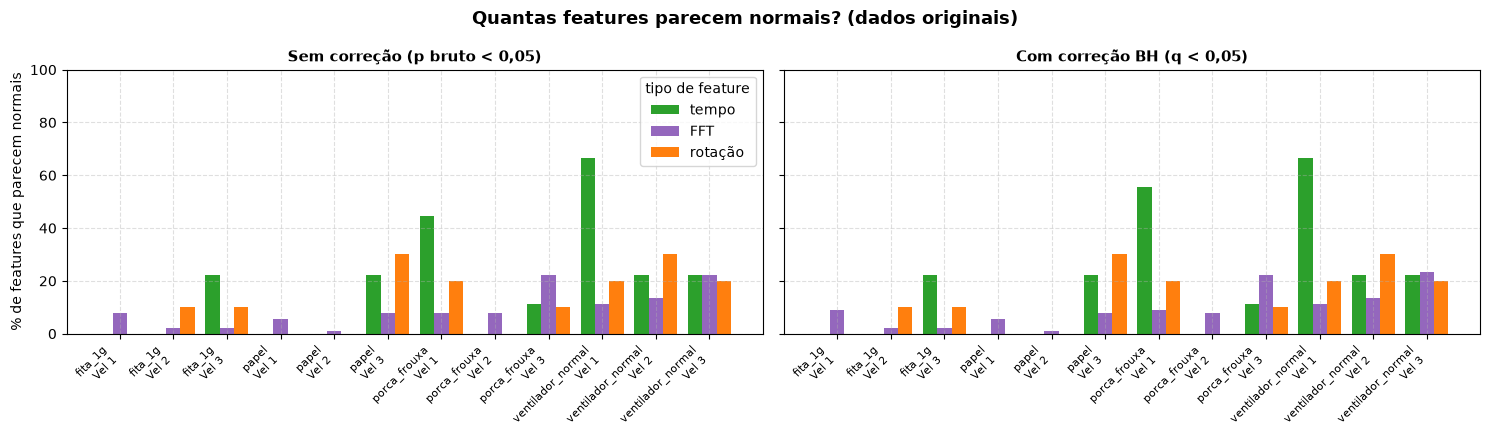

In [12]:
display(resumir_normalidade(resultado_original).round(1))
plotar_percentual_de_normais(resultado_original, "Quantas features parecem normais? (dados originais)")

### 5.1 — Mapa: onde está o desvio da normalidade

**O que buscamos:** ver **quais features** (não só quantas) se afastam da normal.

Cada quadrado é uma feature num grupo (condição e velocidade). A cor é a estatística **W do Shapiro-Wilk**, que vai de 0 a 1:

* **W perto de 1 (amarelo):** a distribuição é parecida com uma normal.
* **W menor (roxo):** o formato se afasta da normal. Quanto menor, mais torta ou "pontuda". Valores abaixo de 0,7 aparecem todos com a cor mais escura.

**O ponto preto** marca as features em que a normalidade foi **rejeitada mesmo após a correção BH** (q < 0,05). Quadrado amarelo com ponto preto é um caso de "o teste rejeita, mas o formato é quase normal", típico de amostra grande.

In [13]:
def montar_matriz_de_w(resultado, colunas):
    """Matrizes (feature x grupo) com W e com a marca de rejeição pelo critério BH."""
    resultado = resultado[resultado["feature"].isin(colunas)].copy()
    resultado["grupo"] = resultado["condicao"].str.replace("ventilador_", "", regex=False) + " V" + resultado["velocidade"].astype(str)
    w = resultado.pivot(index="feature", columns="grupo", values="W").reindex(colunas)
    rejeitada = resultado.pivot(index="feature", columns="grupo", values="nao_normal_bh").reindex(colunas)
    ordem = (resultado[["grupo", "condicao", "velocidade"]].drop_duplicates().sort_values(["condicao", "velocidade"])["grupo"].tolist())
    return w[ordem], rejeitada[ordem]


def plotar_mapa_de_w(resultado, paineis, titulo):
    """Mapa de cores do W. 'paineis' é uma lista de (título, lista de features), um painel por item."""
    altura = 0.22 * max(len(colunas) for _, colunas in paineis) + 2
    fig, axs = plt.subplots(1, len(paineis), figsize=(6.2 * len(paineis), altura), squeeze=False)
    fig.subplots_adjust(wspace=0.75, left=0.12, right=0.88)
    for ax, (subtitulo, colunas) in zip(axs[0], paineis):
        w, rejeitada = montar_matriz_de_w(resultado, colunas)
        imagem = ax.imshow(w.to_numpy(dtype=float), cmap="viridis", vmin=0.7, vmax=1.0, aspect="auto")
        ax.set_xticks(range(w.shape[1]))
        ax.set_xticklabels(w.columns, rotation=40, ha="right", fontsize=8)
        ax.set_yticks(range(w.shape[0]))
        ax.set_yticklabels(w.index, fontsize=7)
        ax.grid(False)
        linhas, colunas_marcadas = np.where(rejeitada.to_numpy(dtype=float) == 1)
        ax.scatter(colunas_marcadas, linhas, s=8, color="black")
        ax.set_title(subtitulo, fontsize=11, fontweight="bold")
    fig.colorbar(imagem, ax=axs[0].tolist(), label="W de Shapiro-Wilk (1 = normal perfeita)", shrink=0.6)
    fig.suptitle(titulo, fontsize=13, fontweight="bold")
    plt.show()

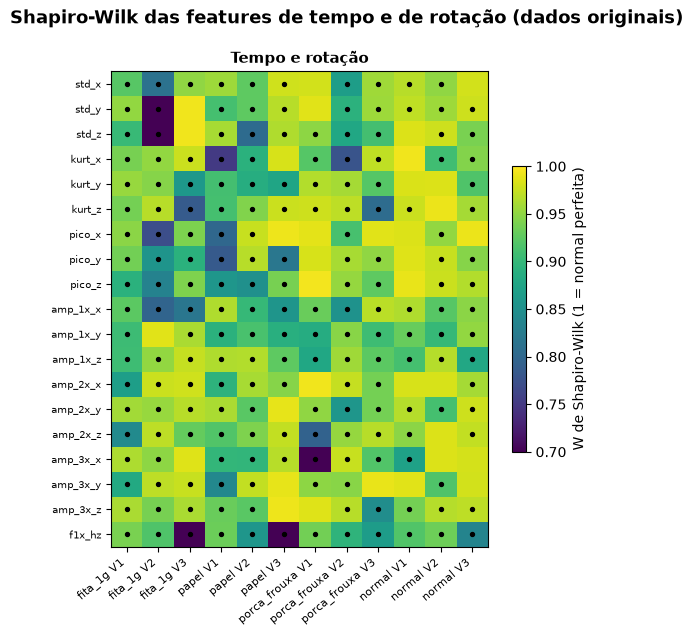

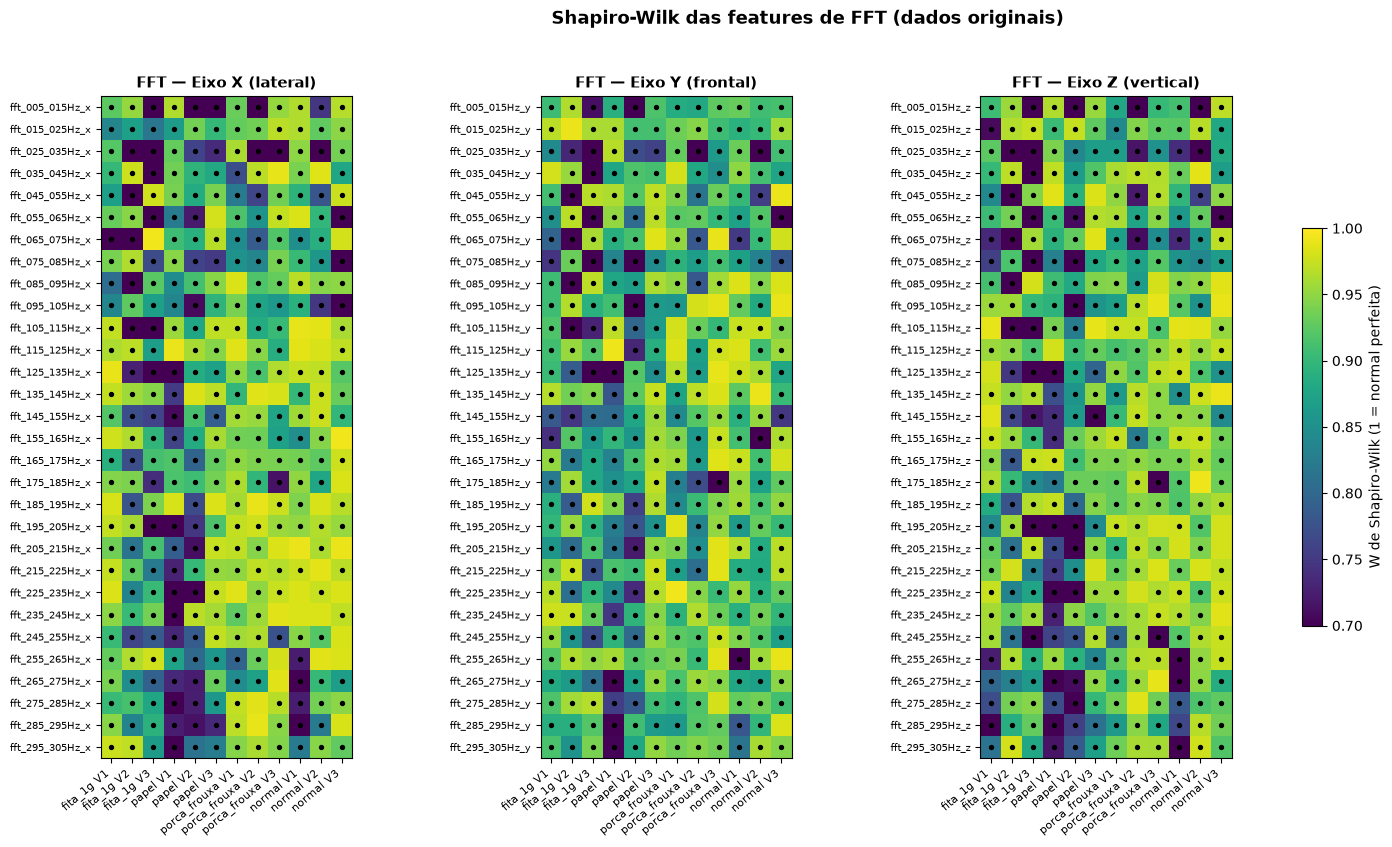

In [14]:
paineis_tempo_rotacao = [("Tempo e rotação", COLUNAS_TEMPO + COLUNAS_ROTACAO)]
paineis_fft = [(f"FFT — {NOMES_EIXOS[eixo]}", colunas_fft_do_eixo(eixo)) for eixo in EIXOS]

plotar_mapa_de_w(resultado_original, paineis_tempo_rotacao, "Shapiro-Wilk das features de tempo e de rotação (dados originais)")
plotar_mapa_de_w(resultado_original, paineis_fft, "Shapiro-Wilk das features de FFT (dados originais)")

### Conclusões do Passo 5 (nesta execução, com os dados novos)

* **Quase nenhuma feature parece normal.** Somando os 12 grupos, cerca de **11%** das features passam no teste com a correção BH. Nos dados antigos eram cerca de 16%.
* **Por tipo:** tempo 20,8%, rotação 12,5% e FFT só 9,5%.
* **O normal é o grupo mais "normal":** de 15,6% a 22,9% das features, conforme a velocidade.
* **As falhas ficam bem abaixo:**
  * **papel Vel 2:** 0,9%, ou seja, 1 feature de 109;
  * **fita Vel 2:** 2,8%;
  * **fita Vel 3:** 4,6%.
* **A correção BH quase não mudou nada** (p bruto e q BH dão praticamente os mesmos números). Quando os p-valores são minúsculos, como aqui, corrigir para 109 testes não muda a conclusão.
* **Por que as falhas são menos normais?** Duas causas aparecem nos passos seguintes:
  * o **aquecimento**, que faz a feature "andar" ao longo da gravação (Passo 7.3);
  * na fita Vel 2, um **trecho inicial** em que a vibração ainda está crescendo (Passo 6.3).
* **Leitura correta:** "não é normal" aqui quer dizer que **o formato não é um sino**. Não quer dizer que os dados estão errados nem que o K-Means não funciona.

## Passo 6 — Assimetria, histogramas e QQ-plots: o quanto e como se afastam

**O que buscamos:** o teste diz *se* a feature se afasta da normal. Agora queremos ver **o quanto** e **de que jeito**.

### 6.1 — W contra assimetria (cada ponto é uma feature num grupo)

* **Eixo horizontal:** a assimetria. A faixa amarela marca o intervalo "pouco torta" (|assimetria| ≤ 1).
* **Eixo vertical:** o W do Shapiro-Wilk. Quanto mais baixo, mais longe da normal.
* **Como interpretar:**
  * ponto **alto e dentro da faixa amarela:** normal ou quase;
  * ponto **baixo e fora da faixa:** claramente não normal e torto;
  * ponto **na faixa amarela, mas com W baixo:** não é por assimetria, e sim por outro defeito (por exemplo, caudas pesadas ou dois grupos misturados).

A tabela embaixo cruza o veredito do teste (BH) com a assimetria, nos quatro casos descritos no Passo 4.

### 6.2 — Histogramas e QQ-plots das features de exemplo

Para cada feature de exemplo (`FEATURES_EXEMPLO`), em `VELOCIDADE_EXEMPLO`:

* **Histograma azul (referência) e vermelho (anomalia):** as barras são os dados; a linha preta é a **normal que mais se parece com eles**. Quanto mais as barras seguem a linha, mais normal.
* **QQ-plot:** os dados padronizados contra uma normal ideal. **Pontos sobre a reta preta = normal.** Pontos que se curvam para cima nas pontas indicam cauda comprida para a direita. Pontos em "S" indicam caudas mais pesadas ou mais leves que a normal.

In [15]:
def selecionar_janelas(features, condicoes, velocidade):
    """Janelas de uma lista de condições numa velocidade."""
    return features[features["condicao"].isin(condicoes) & (features["velocidade"] == velocidade)]


def plotar_scatter_w_e_assimetria(resultado, titulo):
    """Cada ponto é uma feature num grupo: eixo x = assimetria, eixo y = W. Mostra o que o teste rejeita mas é quase simétrico."""
    validos = resultado[resultado["p_bruto"].notna()]
    fig, ax = plt.subplots(figsize=(9, 6))
    for tipo, cor in CORES_TIPO.items():
        parte = validos[validos["tipo"] == tipo]
        ax.scatter(parte["assimetria"], parte["W"], s=14, alpha=0.5, color=cor, label=tipo)
    ax.axvline(LIMITE_ASSIMETRIA, color="black", linestyle="--")
    ax.axvline(-LIMITE_ASSIMETRIA, color="black", linestyle="--")
    ax.axvspan(-LIMITE_ASSIMETRIA, LIMITE_ASSIMETRIA, color="gold", alpha=0.12)
    ax.set_xlabel("assimetria (0 = simétrica; positiva = cauda comprida para a direita)")
    ax.set_ylabel("W de Shapiro-Wilk (1 = normal perfeita)")
    ax.legend(title="tipo de feature")
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()


def contar_casos_de_assimetria_e_teste(resultado):
    """Cruza o veredito do teste (BH) com a assimetria: as quatro combinações possíveis."""
    validos = resultado[resultado["p_bruto"].notna()]
    tabela = pd.crosstab(
        validos["nao_normal_bh"].map({True: "teste rejeita a normal", False: "teste não rejeita"}),
        validos["torta"].map({True: "|assimetria| > limite (torta)", False: "|assimetria| <= limite"}),
    )
    return tabela

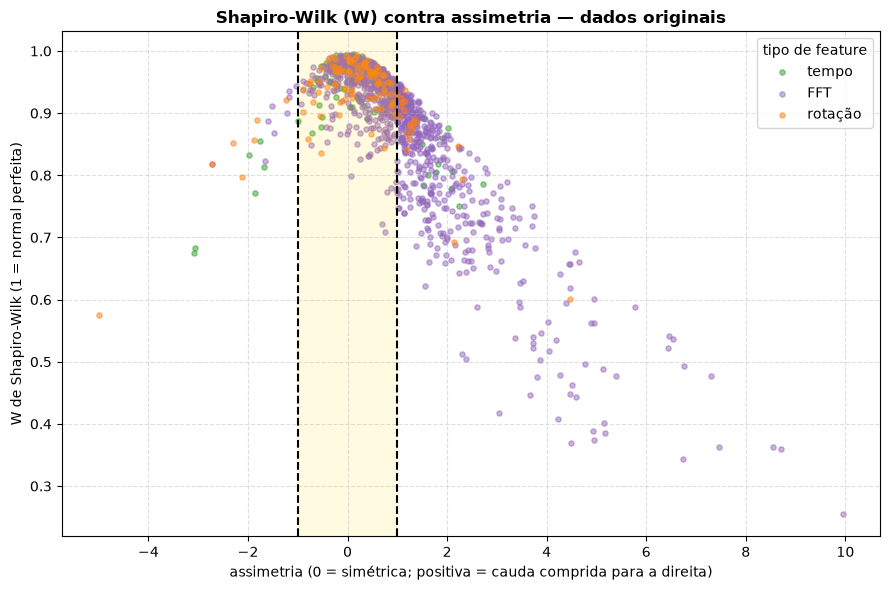

torta,|assimetria| <= limite,|assimetria| > limite (torta)
nao_normal_bh,,
teste não rejeita,138,0
teste rejeita a normal,666,504


In [16]:
plotar_scatter_w_e_assimetria(resultado_original, "Shapiro-Wilk (W) contra assimetria — dados originais")
display(contar_casos_de_assimetria_e_teste(resultado_original))

In [17]:
def plotar_histogramas_e_qq(features, condicoes_ref, condicao, velocidade, colunas_exemplo):
    """Para cada feature: histograma da referência, histograma da anomalia (ambos com a normal ajustada) e QQ-plot das duas."""
    fig, axs = plt.subplots(len(colunas_exemplo), 3, figsize=(16, 3.3 * len(colunas_exemplo)), squeeze=False)
    for i, coluna in enumerate(colunas_exemplo):
        grupos = ((COR_REFERENCIA, condicoes_ref, "referência"), (COR_COMPARADA, [condicao], condicao))
        for j, (cor, condicoes, rotulo) in enumerate(grupos):
            valores = selecionar_janelas(features, condicoes, velocidade)[coluna].to_numpy()
            ax = axs[i, j]
            ax.hist(valores, bins=15, density=True, color=cor, alpha=0.6)
            eixo_x = np.linspace(valores.min(), valores.max(), 200)
            ax.plot(eixo_x, norm.pdf(eixo_x, valores.mean(), valores.std(ddof=1)), color="black", linewidth=1.5, label="normal ajustada")
            ax.set_title(f"{coluna} — {rotulo}", fontsize=10, fontweight="bold")
            ax.set_ylabel("densidade")
            if i == 0 and j == 0:
                ax.legend(fontsize=8)
            padronizados = np.sort((valores - valores.mean()) / valores.std(ddof=1))
            teoricos = norm.ppf((np.arange(1, len(valores) + 1) - 0.5) / len(valores))
            axs[i, 2].scatter(teoricos, padronizados, s=12, color=cor, alpha=0.7, label=rotulo)
        limite = [-3.5, 3.5]
        axs[i, 2].plot(limite, limite, color="black", linewidth=1)
        axs[i, 2].set_title(f"{coluna} — QQ-plot", fontsize=10, fontweight="bold")
        axs[i, 2].set_xlabel("quantil esperado se fosse normal")
        axs[i, 2].set_ylabel("quantil observado (padronizado)")
        axs[i, 2].legend(fontsize=8)
    fig.suptitle(f"Vel {velocidade} — formato das distribuições", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

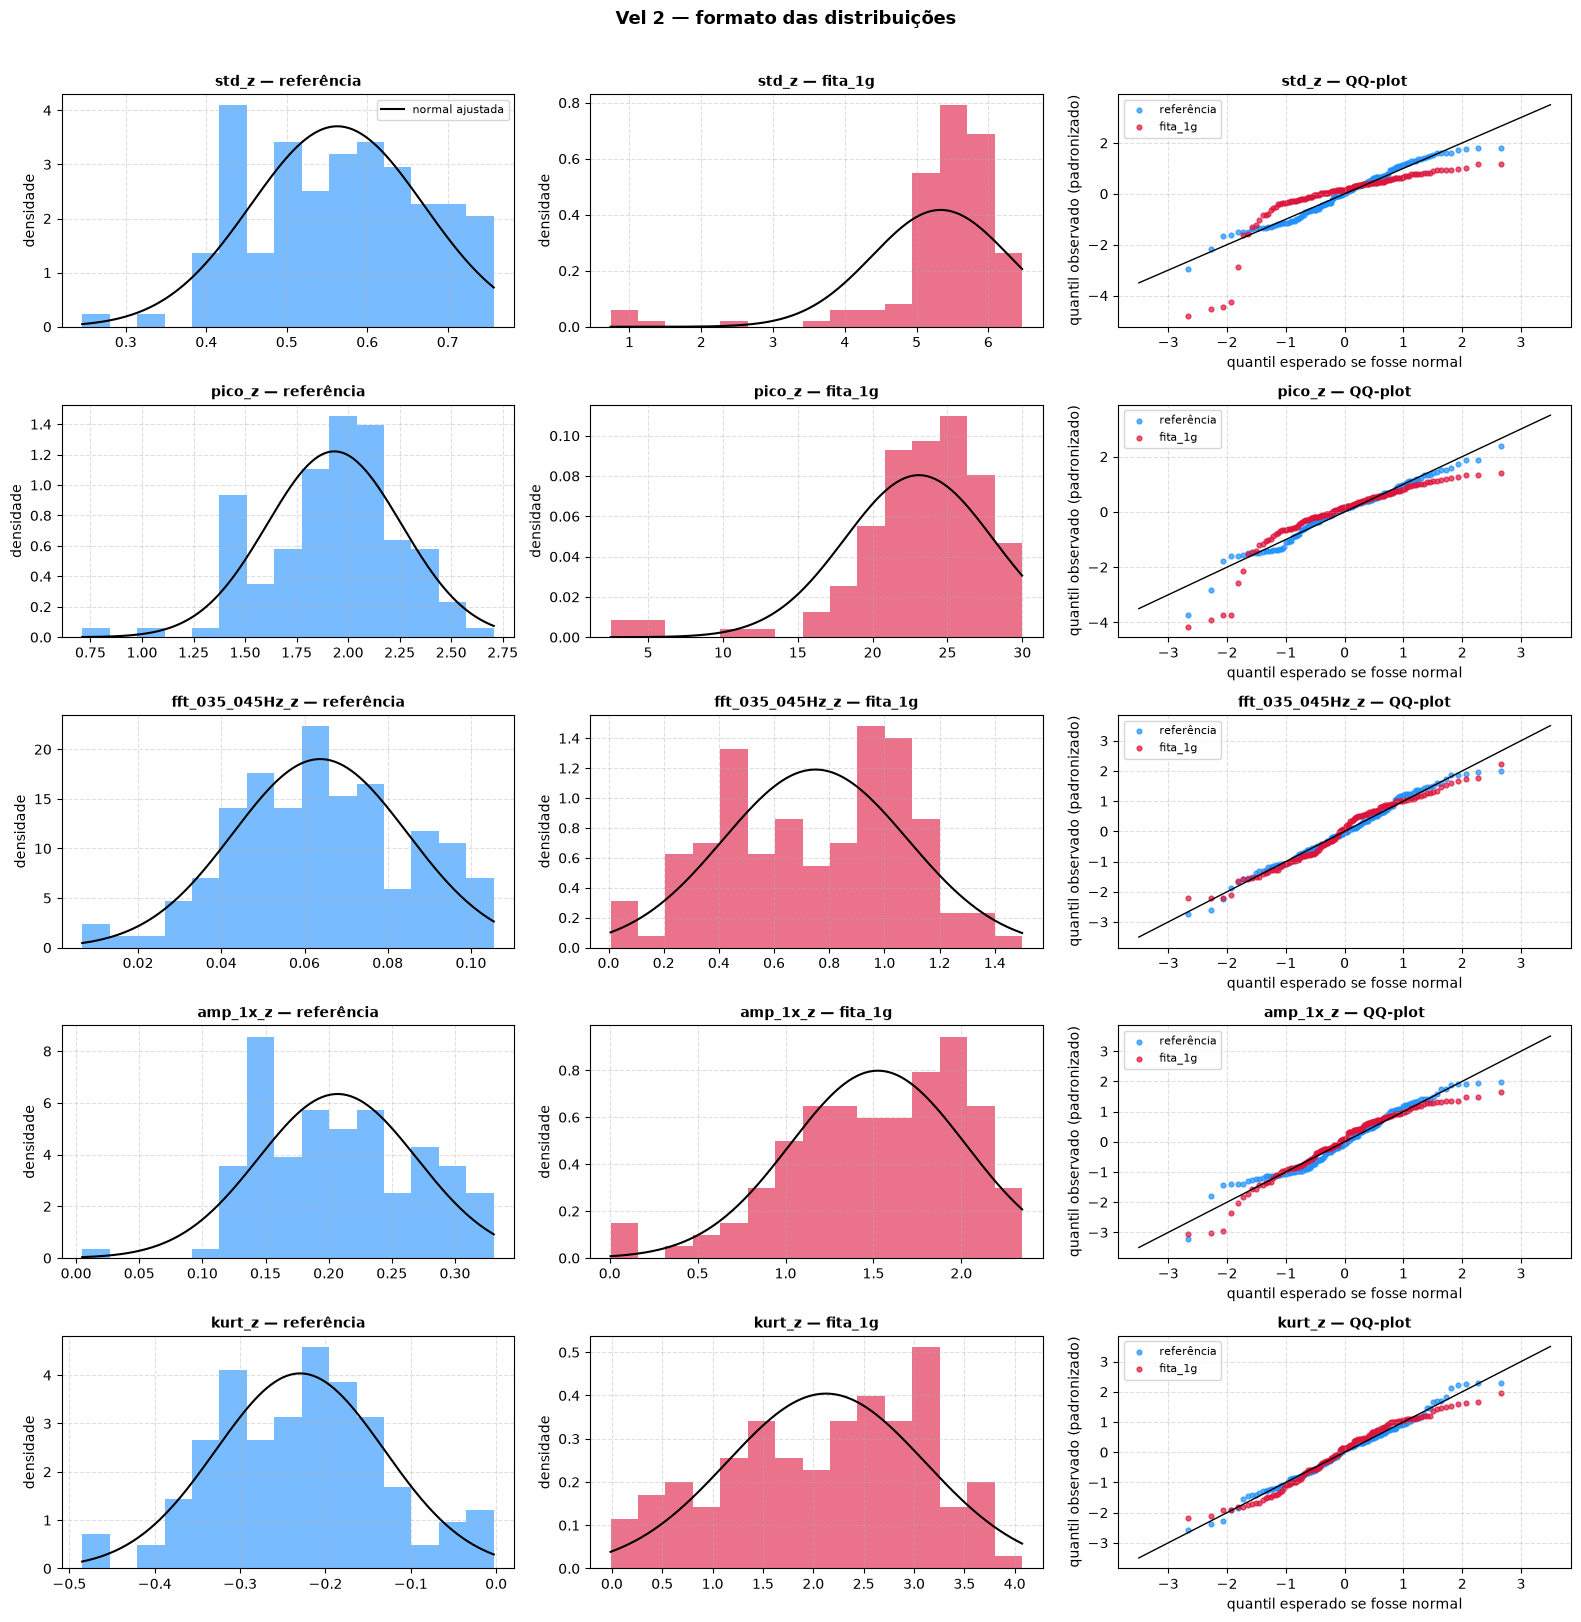

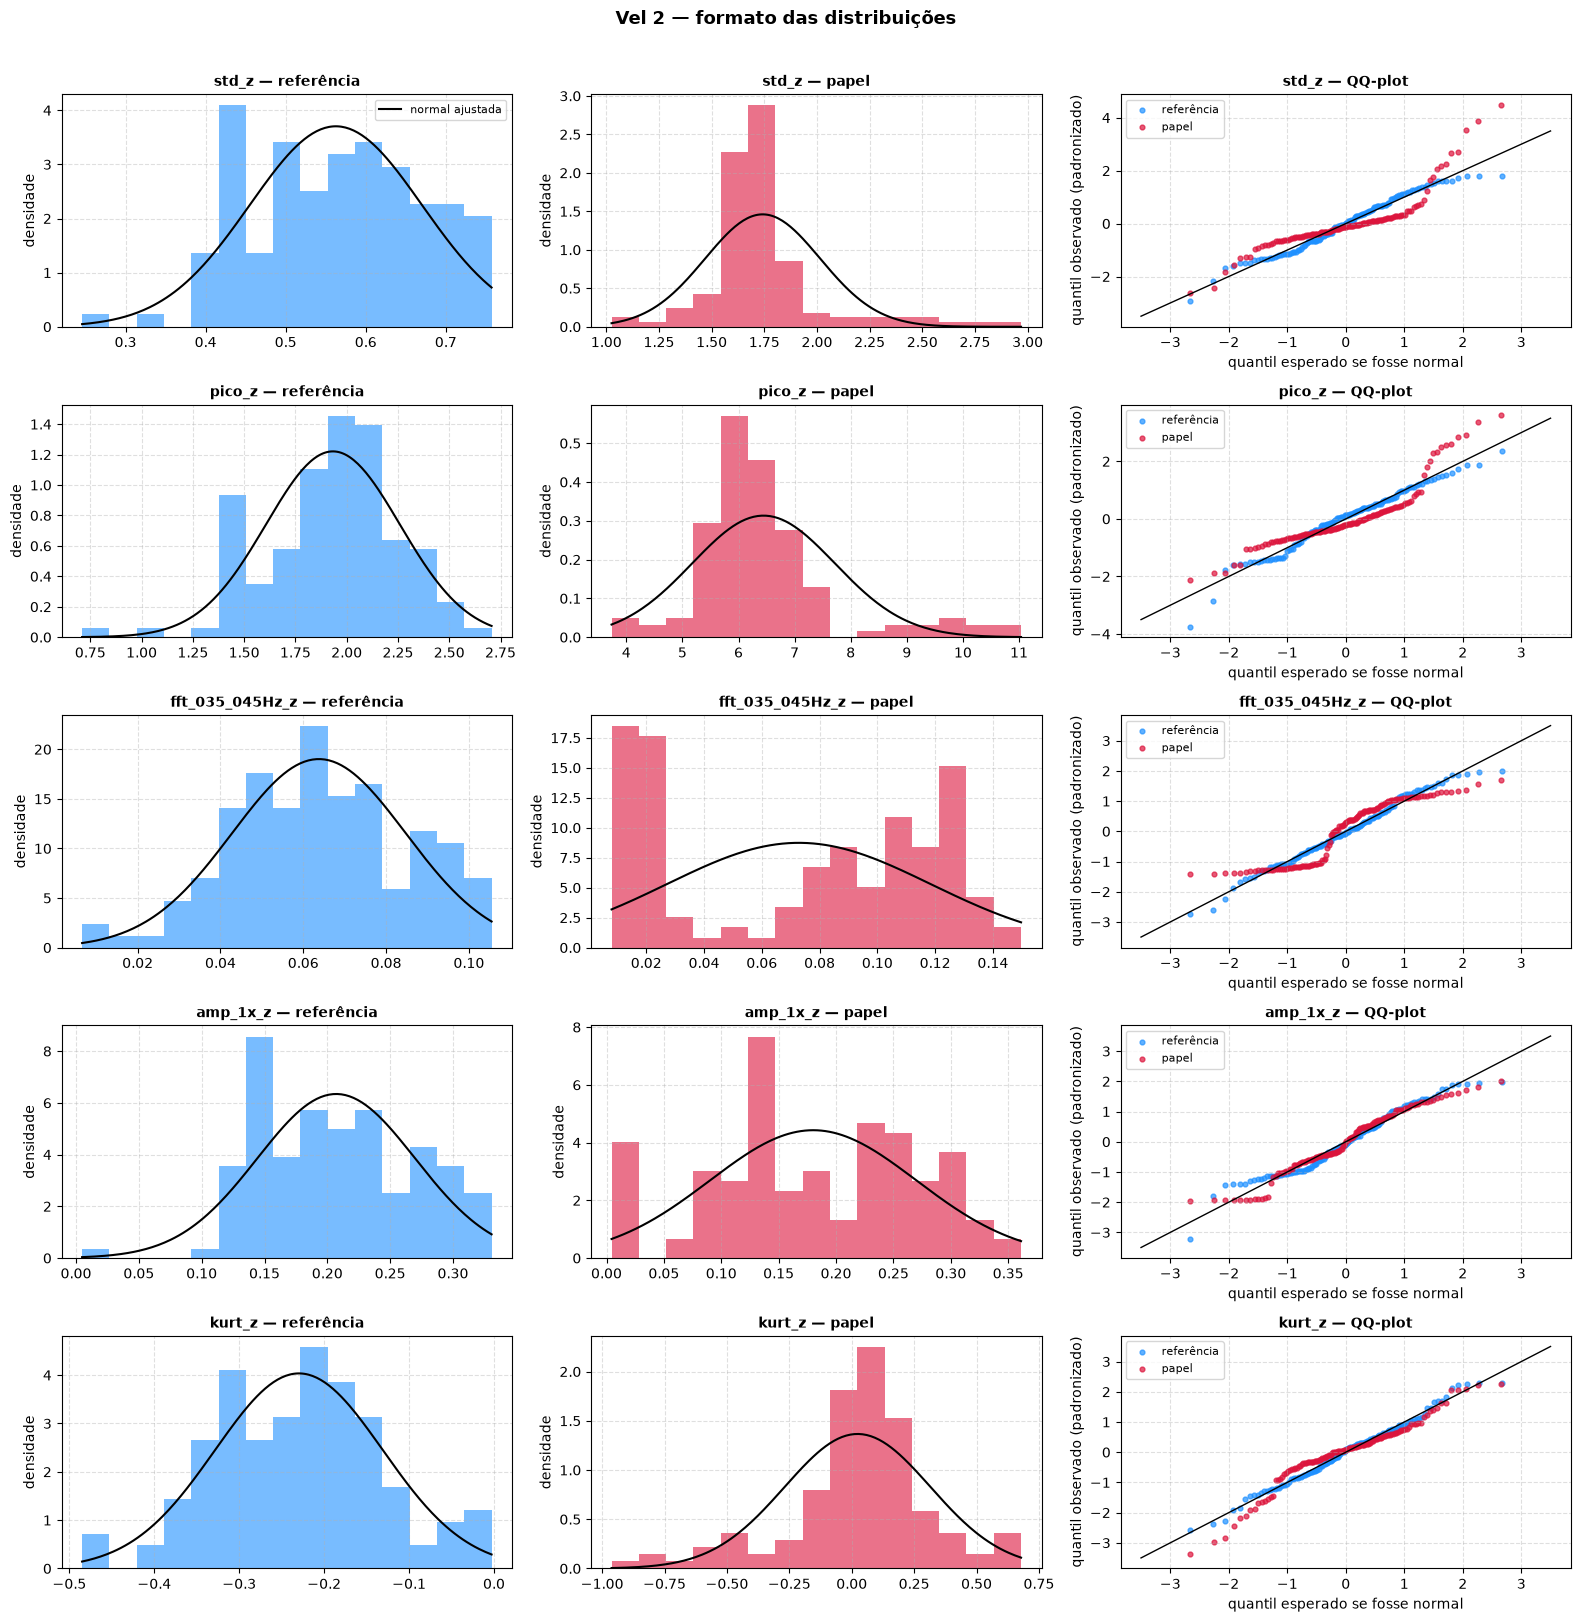

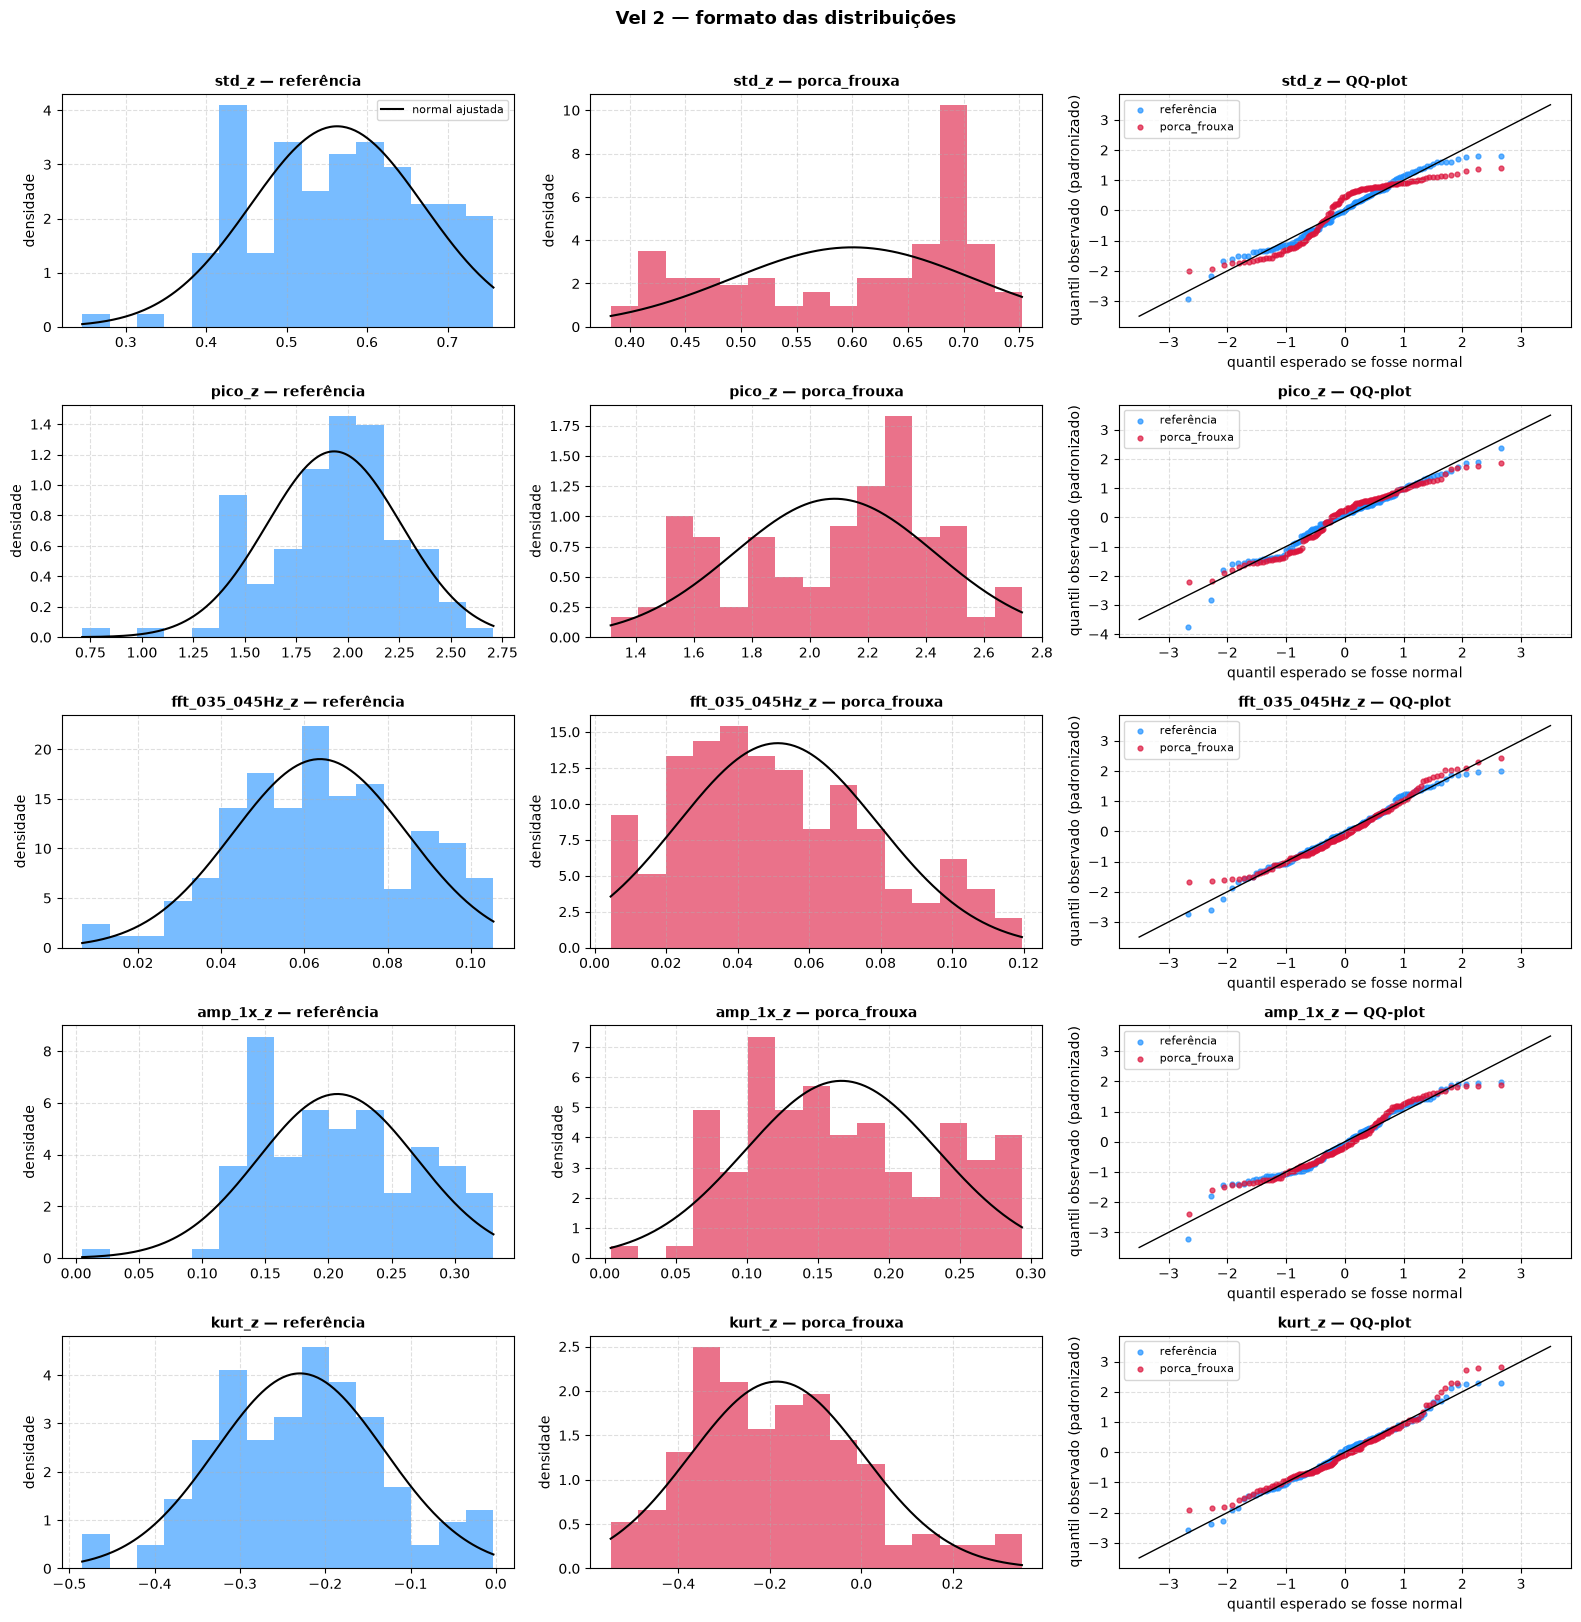

In [18]:
for condicao in condicoes_comparadas:
    plotar_histogramas_e_qq(features, CONDICOES_REFERENCIA, condicao, VELOCIDADE_EXEMPLO, FEATURES_EXEMPLO)

### 6.3 — Janelas atípicas: uma janela estranha pode estragar um grupo inteiro

**O que buscamos:** a assimetria e o Shapiro-Wilk são muito sensíveis a **uma única janela fora do normal**. Com cerca de 110 janelas, um só valor gigante já puxa a assimetria para perto do máximo possível (cerca de 10) e derruba o W. Vamos achar essas janelas.

**Como:** para cada feature, medimos o quanto cada janela se afasta da **mediana do grupo**, em unidades de "desvio robusto" (o MAD, que, ao contrário do desvio padrão, **não é puxado pelo próprio valor extremo**). Valores acima de `LIMITE_Z_ROBUSTO` são extremos. Uma janela é **atípica** quando tem pelo menos `MIN_FEATURES_ATIPICAS` features extremas ao mesmo tempo.

**Por que olhar a janela e não a feature:** uma janela com muitas features extremas de uma vez indica um **evento no sinal** (por exemplo, mexer no ventilador, uma batida, ligar ou desligar), e não uma flutuação normal de uma feature.

**Como ler a tabela:**

* `janela` e `inicio_s`: onde a janela está dentro da base (a janela 0 é o início da gravação).
* `features_extremas`: em quantas das 109 features ela é extrema.
* Janelas **no começo ou no fim** da gravação são suspeitas de manuseio. Confira no sinal bruto antes de decidir cortar.

A segunda parte refaz o teste de normalidade **sem essas janelas**, só nos grupos afetados, para mostrar o tamanho do estrago.

In [19]:
def encontrar_janelas_atipicas(features, colunas, limite_z=LIMITE_Z_ROBUSTO, min_features=MIN_FEATURES_ATIPICAS):
    """Janelas com muitas features extremas ao mesmo tempo, dentro do próprio grupo (condição x velocidade).

    Uma feature é extrema numa janela quando ela fica a mais de limite_z desvios robustos da mediana do grupo.
    O desvio robusto é 1,4826 x MAD (mediana dos desvios absolutos), que não é puxado pelos valores extremos.
    """
    linhas = []
    for (condicao, velocidade), grupo in features.groupby(["condicao", "velocidade"]):
        valores = grupo[colunas]
        mediana = valores.median()
        desvio_robusto = 1.4826 * (valores - mediana).abs().median()
        z_robusto = (valores - mediana) / desvio_robusto.replace(0, np.nan)
        n_extremas = (z_robusto.abs() > limite_z).sum(axis=1)
        for indice in n_extremas[n_extremas >= min_features].index:
            linhas.append({
                "condicao": condicao, "velocidade": velocidade, "janela": int(grupo.loc[indice, "janela"]),
                "inicio_s": int(grupo.loc[indice, "janela"]) * JANELA_S, "features_extremas": int(n_extremas[indice]),
                "indice": indice,
            })
    colunas_tabela = ["condicao", "velocidade", "janela", "inicio_s", "features_extremas", "indice"]
    return pd.DataFrame(linhas, columns=colunas_tabela).sort_values(["condicao", "velocidade", "janela"])

In [20]:
janelas_atipicas = encontrar_janelas_atipicas(features, COLUNAS_TODAS)
duracao_por_base = catalogo.set_index(["condicao", "velocidade"])["duracao_s"]

if janelas_atipicas.empty:
    print("Nenhuma janela atípica encontrada com estes limites.")
else:
    display(janelas_atipicas.drop(columns="indice").set_index(["condicao", "velocidade"]))
    for condicao, velocidade in janelas_atipicas[["condicao", "velocidade"]].drop_duplicates().itertuples(index=False):
        total = int(duracao_por_base[(condicao, velocidade)] // JANELA_S)
        print(f"{condicao} Vel {velocidade}: a base tem {total} janelas (de 0 a {total - 1}).")

janela  inicio_s  features_extremas
condicao velocidade                                     
fita_1g  2                2        10                 12
         2                5        25                 10
         2                7        35                 20
         2                8        40                 12
         2                9        45                 15
         2               10        50                 15
         2               11        55                 10
         2               12        60                 14
         2               13        65                 10
         2               14        70                 16
         2               15        75                 13
         2               16        80                 15
         2               17        85                 11
         2               19        95                 15
         2               20       100                 15
         2               22       110                 13
         2               23       115                 15
         2               24       120                 13
         2               25       125                 11
         2               26       130                 10
         2               30       150                 12
         2               31       155                 14
         2               34       170                 17
         2               35       175                 15
         2               36       180                 14
         2               38       190                 14
         2               41       205                 15
         2               43       215                 12
         2               48       240                 15
         2               50       250                 10
         3                0         0                 20
         3               35       175                 10
         3               67       335                 14
         3              107       535                 22
         3              109       545                 16
papel    3                0         0                 10

fita_1g Vel 2: a base tem 129 janelas (de 0 a 128).
fita_1g Vel 3: a base tem 126 janelas (de 0 a 125).
papel Vel 3: a base tem 128 janelas (de 0 a 127).


In [21]:
def testar_sem_janelas_atipicas(features, janelas_atipicas, colunas):
    """Refaz o teste de normalidade sem as janelas atípicas, só nos grupos que tinham alguma."""
    grupos_afetados = janelas_atipicas[["condicao", "velocidade"]].drop_duplicates()
    limpa = features.drop(index=janelas_atipicas["indice"])
    limpa = limpa.merge(grupos_afetados, on=["condicao", "velocidade"])
    antes = features.merge(grupos_afetados, on=["condicao", "velocidade"])
    return testar_normalidade(antes, colunas), testar_normalidade(limpa, colunas)


def comparar_com_e_sem_atipicas(resultado_com, resultado_sem):
    """Resumo lado a lado, por grupo afetado, com e sem as janelas atípicas."""
    colunas_resumo = ["features testadas", "% normais (q BH)", "% tortas (|assim.| > limite)", "mediana |assimetria|"]
    com = resumir_normalidade(resultado_com)[colunas_resumo]
    sem = resumir_normalidade(resultado_sem)[colunas_resumo]
    return pd.concat({"com as atípicas": com, "sem as atípicas": sem}, axis=1).swaplevel(axis=1).sort_index(axis=1)

In [22]:
if not janelas_atipicas.empty:
    resultado_com, resultado_sem = testar_sem_janelas_atipicas(features, janelas_atipicas, COLUNAS_TODAS)
    display(comparar_com_e_sem_atipicas(resultado_com, resultado_sem).round(1))

% normais (q BH)                  \
                     com as atípicas sem as atípicas   
condicao velocidade                                    
fita_1g  2                       2.8            18.3   
         3                       4.6             7.3   
papel    3                      11.0            19.3   

                    % tortas (|assim.| > limite)                  \
                                 com as atípicas sem as atípicas   
condicao velocidade                                                
fita_1g  2                                  48.6            53.2   
         3                                  59.6            51.4   
papel    3                                  40.4            21.1   

                    features testadas                 mediana |assimetria|  \
                      com as atípicas sem as atípicas      com as atípicas   
condicao velocidade                                                          
fita_1g  2                      109.0           109.0                  1.0   
         3                      109.0           109.0                  1.2   
papel    3                      109.0           109.0                  0.8   

                                     
                    sem as atípicas  
condicao velocidade                  
fita_1g  2                      1.1  
         3                      1.0  
papel    3                      0.7

### Conclusões do Passo 6 (dados novos)

**O quanto se afastam (6.1):**
* Dos 1.308 testes:
  * **138** não rejeitam a normalidade;
  * **666** rejeitam, mas a feature **não é torta** (|assimetria| ≤ 1);
  * **504 (39%)** são claramente tortos.
* A maior parte das rejeições é de formato **um pouco fora do sino**, e não de cauda enorme.

**Como se afastam (6.2, exemplo da Vel 2):**
* **`std_z` e `pico_z` da fita** têm a cauda **para a esquerda**: a maioria das janelas fica entre 5 e 6,5 m/s², e algumas poucas ficam bem abaixo, entre 1 e 4. São as janelas do começo da gravação (6.3).
* **`fft_035_045Hz_z` da fita** tem **dois montes**. Uma feature que passa parte do tempo num nível e parte em outro (ciclo ou aquecimento) forma esse desenho.
* **No normal**, os histogramas ficam mais perto do sino, e os pontos do QQ-plot acompanham a reta.

**Janelas atípicas (6.3):**
* **Fita Vel 2: 30 janelas atípicas, todas nos primeiros 250 s** (janelas 2 a 50). **Não são falhas de leitura.** Nesse trecho a vibração da fita **ainda está crescendo**: o `std_x` sobe de cerca de 3,8 para cerca de 10 m/s² enquanto a rotação passa de 18,5 para 20 Hz. Depois disso ela se estabiliza. O detector de atípicas compara cada janela com a mediana da base, então marca o trecho de subida inteiro.
* **Janela 0 da fita Vel 3 e do papel Vel 3** (5 a 10 s da gravação): a rotação ainda não se estabilizou (`f1x_hz` de 21,8 e 24,8 Hz contra a mediana de 23,6 e 22,8) e a amplitude da 1X é baixa. O motor ainda está acelerando.
* **Janelas 35, 67, 107 e 109 da fita Vel 3:** valores de pico um pouco mais altos, com a curtose normal. Não há sinal de falha de leitura.
* **Tirar as atípicas não resolve:** na fita Vel 2 as normais sobem de 2,8% para 18,3%, mas as tortas **sobem** de 48,6% para 53,2%.

**Decisão:** **manter todas as janelas.** São comportamento real do ventilador (aquecimento e partida), e o modelo precisa aprender a lidar com ele. As falhas de leitura de verdade já foram removidas pelo corte de 5 s do começo e do fim.

## Passo 7 — Autocorrelação: as janelas são independentes?

**O que buscamos:** medir o quanto as ressalvas da Escolha 2 pesam nos nossos dados.

**A pergunta:** se uma janela tem um valor alto numa feature, a **janela seguinte** também tende a ter? Isso se mede pela **autocorrelação de lag 1**: a correlação de cada feature com ela mesma deslocada em uma janela, dentro de cada base.

* **Perto de 0:** janelas vizinhas são independentes. Os p-valores são confiáveis.
* **Perto de 1:** janelas vizinhas são cópias uma da outra (por exemplo, deriva lenta). Os p-valores ficam **otimistas demais**.
* **Janelas equivalentes:** uma estimativa de quantas janelas "realmente independentes" a base vale, calculada como n × (1 − r) / (1 + r), em que r é a autocorrelação mediana (valores negativos contam como 0).

**Cuidado ao ler:** com poucas janelas por base, a autocorrelação de cada feature tem ruído de mais ou menos 0,1. Só consideramos autocorrelação relevante se ela ficar **claramente acima de 0,2 ou 0,3**.

In [23]:
def calcular_autocorrelacao_lag1(features, colunas):
    """Correlação de cada feature com ela mesma na janela seguinte, dentro de cada base. Devolve (base x feature)."""
    linhas = {}
    for base, grupo in features.groupby("base", sort=False):
        grupo = grupo.sort_values("janela")
        linhas[base] = {c: grupo[c].autocorr(lag=1) for c in colunas}
    return pd.DataFrame(linhas).T


def resumir_autocorrelacao(autocorrelacao, features):
    """Por base: mediana e percentil 90 da autocorrelação, e quantas janelas 'independentes' isso equivale."""
    n_janelas = features.groupby("base", sort=False).size()
    mediana = autocorrelacao.median(axis=1)
    resumo = pd.DataFrame({
        "janelas": n_janelas,
        "autocorrelacao mediana": mediana,
        "autocorrelacao p90": autocorrelacao.quantile(0.9, axis=1),
    })
    resumo["janelas equivalentes"] = n_janelas * (1 - mediana.clip(lower=0)) / (1 + mediana.clip(lower=0))
    return resumo

In [24]:
autocorrelacao = calcular_autocorrelacao_lag1(features, COLUNAS_TODAS)
display(resumir_autocorrelacao(autocorrelacao, features).round(2))

,janelas,autocorrelacao mediana,autocorrelacao p90,janelas equivalentes
fita_1g_vel_1,123,0.42,0.75,50.20
fita_1g_vel_2,129,0.44,0.70,49.87
fita_1g_vel_3,126,-0.00,0.31,126.00
papel_vel_1,125,0.48,0.79,43.77
papel_vel_2,126,0.63,0.85,28.61
papel_vel_3,128,0.05,0.49,116.60
porca_frouxa_vel_1,127,0.16,0.59,92.37
porca_frouxa_vel_2,127,0.22,0.77,80.90
porca_frouxa_vel_3,128,-0.13,0.18,128.00
ventilador_normal_vel_1,127,0.30,0.70,67.93


### 7.2 — Ciclo lento: o que está por trás da autocorrelação

**O que buscamos:** se a autocorrelação não for perto de 0 (positiva **ou negativa**), algo repete de janela em janela. Vamos procurar **um ciclo lento** na intensidade da vibração.

**Como:** para cada base, medimos o desvio padrão do sinal a cada `BLOCO_MODULACAO_S` (0,25 s), o que dá uma curva de "quanto o ventilador vibra" ao longo do tempo. Depois olhamos **qual período se repete mais** nessa curva.

**Como ler:**

* **Gráfico da esquerda:** se a curva sobe e desce com regularidade, existe um ciclo.
* **Gráfico da direita:** o pico mostra o **período do ciclo** em segundos. As linhas marcam o tamanho da janela (5 s) e de duas janelas (10 s).
* **Tabela:** o período dominante, o quanto a intensidade oscila em torno da média e a razão entre os valores altos e baixos do ciclo.

**Por que isso importa para nossas janelas de 5 s:** se o ciclo dura cerca de 10 s, **cada janela pega só uma metade do ciclo**. Uma janela cai na fase "forte", a seguinte na fase "fraca", e assim por diante. Isso gera autocorrelação **negativa**, distribuições **achatadas ou com dois montes** (não parecidas com o sino) e mais variação **dentro** de uma mesma condição.

In [25]:
def medir_ciclo_lento(df, eixo=EIXO_MODULACAO, bloco_s=BLOCO_MODULACAO_S):
    """Intensidade (desvio padrão) a cada bloco curto e o espectro dessa série.

    Devolve (tempo_s, intensidade, periodos_s, forca_do_ciclo), com os períodos de FAIXA_PERIODO_MODULACAO_S.
    """
    tamanho = int(bloco_s * TAXA_AMOSTRAGEM_HZ)
    n_blocos = len(df) // tamanho
    blocos = df[eixo].to_numpy()[: n_blocos * tamanho].reshape(n_blocos, tamanho)
    intensidade = blocos.std(axis=1, ddof=1)
    espectro = np.abs(np.fft.rfft((intensidade - intensidade.mean()) * np.hanning(n_blocos)))
    frequencias_ciclo = np.fft.rfftfreq(n_blocos, d=bloco_s)
    na_faixa = (frequencias_ciclo >= 1 / FAIXA_PERIODO_MODULACAO_S[1]) & (frequencias_ciclo <= 1 / FAIXA_PERIODO_MODULACAO_S[0])
    periodos = 1 / frequencias_ciclo[na_faixa]
    return np.arange(n_blocos) * bloco_s, intensidade, periodos, espectro[na_faixa]


def resumir_ciclo_lento(bases):
    """Por base: o período do ciclo dominante e o quanto a intensidade oscila ao longo dele."""
    linhas = {}
    for nome, df in bases.items():
        _, intensidade, periodos, forca = medir_ciclo_lento(df)
        linhas[nome] = {
            "periodo dominante (s)": periodos[forca.argmax()],
            "oscilação (desvio / média, %)": 100 * intensidade.std() / intensidade.mean(),
            "pico / vale (percentil 95 / 5)": np.percentile(intensidade, 95) / np.percentile(intensidade, 5),
        }
    return pd.DataFrame(linhas).T


def plotar_ciclo_lento(bases, duracao_s=120):
    """Por base: intensidade ao longo do tempo (esquerda) e força de cada período (direita)."""
    fig, axs = plt.subplots(len(bases), 2, figsize=(14, 2.6 * len(bases)), squeeze=False)
    for i, (nome, df) in enumerate(bases.items()):
        tempo, intensidade, periodos, forca = medir_ciclo_lento(df)
        axs[i, 0].plot(tempo, intensidade, linewidth=0.8, color="slategray")
        axs[i, 0].set_xlim(0, duracao_s)
        axs[i, 0].set_title(f"{nome} — desvio padrão de {EIXO_MODULACAO} a cada {BLOCO_MODULACAO_S} s", fontsize=10, fontweight="bold")
        axs[i, 0].set_ylabel(UNIDADE)
        axs[i, 1].plot(periodos, forca, color="slategray")
        axs[i, 1].axvline(JANELA_S, color="crimson", linestyle="--", label=f"janela de {JANELA_S} s")
        axs[i, 1].axvline(2 * JANELA_S, color="black", linestyle=":", label=f"2 janelas ({2 * JANELA_S} s)")
        axs[i, 1].set_title("Força de cada período do ciclo", fontsize=10, fontweight="bold")
        if i == 0:
            axs[i, 1].legend(fontsize=8)
    axs[-1, 0].set_xlabel("Tempo (s)")
    axs[-1, 1].set_xlabel("Período do ciclo (s)")
    plt.tight_layout()
    plt.show()

,periodo dominante (s),"oscilação (desvio / média, %)",pico / vale (percentil 95 / 5)
fita_1g_vel_1,18.77,31.44,2.55
fita_1g_vel_2,11.55,20.34,1.83
fita_1g_vel_3,9.46,25.33,2.19
papel_vel_1,19.06,12.90,1.46
papel_vel_2,12.66,18.75,1.74
papel_vel_3,9.88,11.15,1.41
porca_frouxa_vel_1,17.72,13.54,1.54
porca_frouxa_vel_2,11.82,20.86,2.03
porca_frouxa_vel_3,9.56,32.81,2.48
ventilador_normal_vel_1,8.96,12.77,1.55


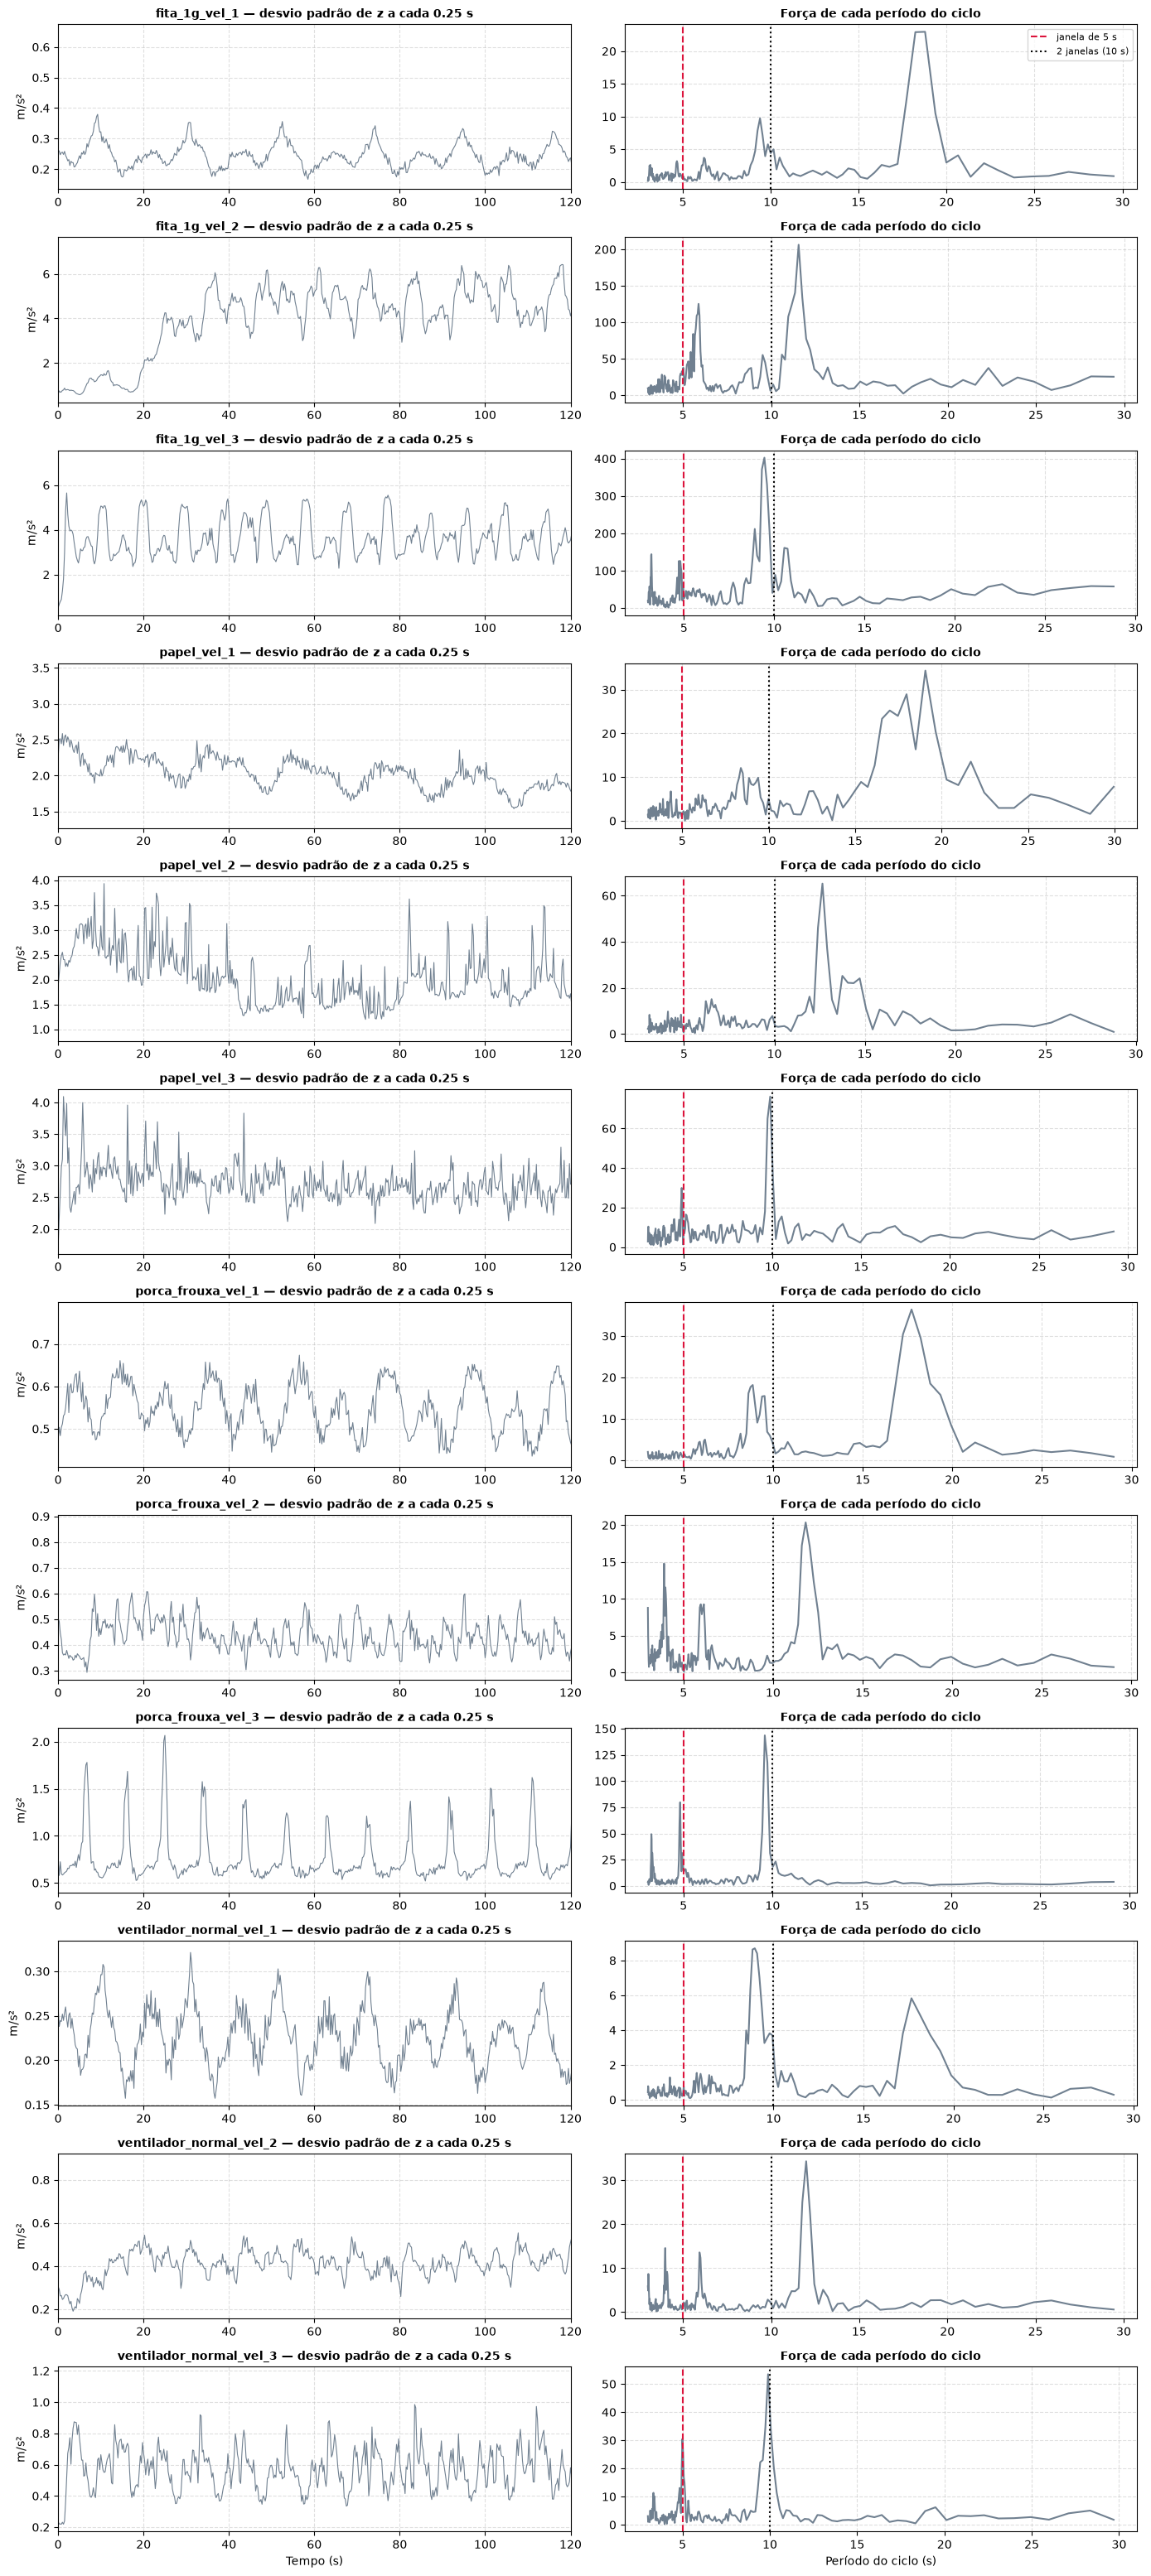

In [26]:
display(resumir_ciclo_lento(bases).round(2))
plotar_ciclo_lento(bases)

### 7.2.1 — O ciclo depende da velocidade?

**O que buscamos:** na tabela acima, o período do ciclo **muda com a velocidade**: fica perto de 18 s na Vel 1, de 12 s na Vel 2 e de 10 s na Vel 3. Se o mecanismo da oscilação for movido pelo **mesmo motor** que gira a hélice (o que é comum em ventiladores de mesa, com uma engrenagem redutora), o ciclo deve durar sempre **o mesmo número de voltas da hélice**.

**Como testamos:** multiplicamos o período do ciclo (em segundos) pela rotação mediana da base (em voltas por segundo, que é o `f1x_hz`). O resultado é **quantas voltas a hélice dá durante um ciclo de oscilação**.

* **Se o número for parecido em todas as bases:** o ciclo acompanha a rotação. Ele é mais lento na Vel 1 e mais rápido na Vel 3.
* **Se uma base der cerca de metade das outras:** o pico escolhido foi o de **meio ciclo** (ida ou volta). Isso acontece quando a vibração tem dois "montes" por ciclo completo.

**Cuidado:** a rotação muda ao longo da gravação (aquecimento), e aqui usamos a mediana. O número é uma aproximação, não uma medida exata da engrenagem.

In [27]:
def relacionar_ciclo_com_rotacao(resumo_ciclo, features):
    """Por base: período do ciclo, rotação mediana e quantas voltas da hélice cabem em um ciclo."""
    rotacao = features.groupby("base")["f1x_hz"].median()
    tabela = pd.DataFrame({
        "periodo dominante (s)": resumo_ciclo["periodo dominante (s)"],
        "rotacao mediana (Hz)": rotacao.reindex(resumo_ciclo.index),
    })
    tabela["voltas da hélice por ciclo"] = tabela["periodo dominante (s)"] * tabela["rotacao mediana (Hz)"]
    return tabela

In [28]:
display(relacionar_ciclo_com_rotacao(resumir_ciclo_lento(bases), features).round(1))

,periodo dominante (s),rotacao mediana (Hz),voltas da hélice por ciclo
fita_1g_vel_1,18.8,11.6,217.8
fita_1g_vel_2,11.6,19.8,228.8
fita_1g_vel_3,9.5,23.6,223.1
papel_vel_1,19.1,12.4,236.4
papel_vel_2,12.7,18.0,227.9
papel_vel_3,9.9,22.8,225.4
porca_frouxa_vel_1,17.7,12.2,216.2
porca_frouxa_vel_2,11.8,19.0,224.6
porca_frouxa_vel_3,9.6,23.4,223.7
ventilador_normal_vel_1,9.0,12.4,111.1


### 7.3 — Tendência (aquecimento) ou ciclo? Separando as duas causas

**O que buscamos:** nos dados novos, existem **duas** causas possíveis para janelas vizinhas serem parecidas:

1. **Tendência lenta (aquecimento):** a rotação sobe ao longo dos 10 minutos e puxa várias features junto. Uma janela fica parecida com a vizinha porque as duas estão no mesmo "momento" da gravação.
2. **Ciclo da oscilação (7.2):** um vai e volta de cerca de 10 a 20 s, ou seja, de 2 a 4 janelas.

**Como separamos:** para cada feature de cada base, calculamos a **tendência** como a mediana móvel de `JANELAS_TENDENCIA` janelas (13 janelas = 65 s). Uma curva tão larga acompanha o aquecimento, mas é larga demais para seguir um ciclo de 10 a 20 s. Depois tiramos essa tendência da feature e calculamos de novo a autocorrelação **no que sobrou** (o resíduo).

**Exemplo:** imagine o `std_z` subindo de 2 para 6 ao longo da gravação, com pequenas subidas e descidas por cima. A tendência é a rampa de 2 a 6. O resíduo são só as subidas e descidas.

**Como ler a tabela:**

* **Autocorrelação alta antes e baixa depois:** a dependência entre janelas vinha da **tendência** (aquecimento).
* **Alta antes e ainda alta depois:** existe dependência de curto prazo que não é tendência.
* **Negativa depois:** sinal do ciclo de oscilação. Uma janela "forte" tende a ser seguida por uma "fraca".

**O gráfico** mostra um exemplo: a feature ao longo da gravação, a tendência por cima e o resíduo embaixo.

In [29]:
def remover_tendencia(features, colunas, janelas_tendencia=JANELAS_TENDENCIA):
    """Para cada base, subtrai de cada feature a sua mediana móvel centrada. Devolve (resíduos, tendências)."""
    residuos, tendencias = [], []
    for _, grupo in features.groupby("base", sort=False):
        grupo = grupo.sort_values("janela")
        tendencia = grupo[colunas].rolling(janelas_tendencia, center=True, min_periods=1).median()
        residuo = grupo.copy()
        residuo[colunas] = grupo[colunas] - tendencia
        residuos.append(residuo)
        tendencias.append(tendencia)
    return pd.concat(residuos), pd.concat(tendencias)


def comparar_autocorrelacao_com_e_sem_tendencia(autocorrelacao, autocorrelacao_residuo, features):
    """Por base: autocorrelação mediana antes e depois de tirar a tendência, e as janelas equivalentes nos dois casos."""
    antes = resumir_autocorrelacao(autocorrelacao, features)
    depois = resumir_autocorrelacao(autocorrelacao_residuo, features)
    return pd.DataFrame({
        "janelas": antes["janelas"],
        "autocorr. mediana (original)": antes["autocorrelacao mediana"],
        "autocorr. mediana (sem tendência)": depois["autocorrelacao mediana"],
        "janelas equivalentes (original)": antes["janelas equivalentes"],
        "janelas equivalentes (sem tendência)": depois["janelas equivalentes"],
    })


def plotar_tendencia_e_residuo(features, residuos, tendencias, base, feature):
    """Uma feature de uma base: valor por janela com a tendência (em cima) e o resíduo (embaixo)."""
    grupo = features[features["base"] == base].sort_values("janela")
    tempo = grupo["janela"] * JANELA_S
    fig, axs = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
    axs[0].plot(tempo, grupo[feature], ".-", color="slategray", linewidth=0.8, label="valor por janela")
    axs[0].plot(tempo, tendencias.loc[grupo.index, feature], color="crimson", linewidth=2.5, label=f"tendência (mediana de {JANELAS_TENDENCIA} janelas)")
    axs[0].set_ylabel(feature)
    axs[0].legend(fontsize=9)
    axs[0].set_title(f"{base} — {feature}: valor e tendência", fontsize=11, fontweight="bold")
    axs[1].plot(tempo, residuos.loc[grupo.index, feature], ".-", color="darkorange", linewidth=0.8)
    axs[1].axhline(0, color="black", linewidth=0.8)
    axs[1].set_ylabel("resíduo")
    axs[1].set_xlabel("Tempo dentro da base (s)")
    axs[1].set_title("Resíduo = valor − tendência (é nele que medimos a autocorrelação de novo)", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

,janelas,autocorr. mediana (original),autocorr. mediana (sem tendência),janelas equivalentes (original),janelas equivalentes (sem tendência)
fita_1g_vel_1,123,0.42,-0.14,50.20,123.0
fita_1g_vel_2,129,0.44,-0.10,49.87,129.0
fita_1g_vel_3,126,-0.00,-0.21,126.00,126.0
papel_vel_1,125,0.48,-0.11,43.77,125.0
papel_vel_2,126,0.63,-0.05,28.61,126.0
papel_vel_3,128,0.05,-0.22,116.60,128.0
porca_frouxa_vel_1,127,0.16,-0.15,92.37,127.0
porca_frouxa_vel_2,127,0.22,-0.44,80.90,127.0
porca_frouxa_vel_3,128,-0.13,-0.39,128.00,128.0
ventilador_normal_vel_1,127,0.30,-0.15,67.93,127.0


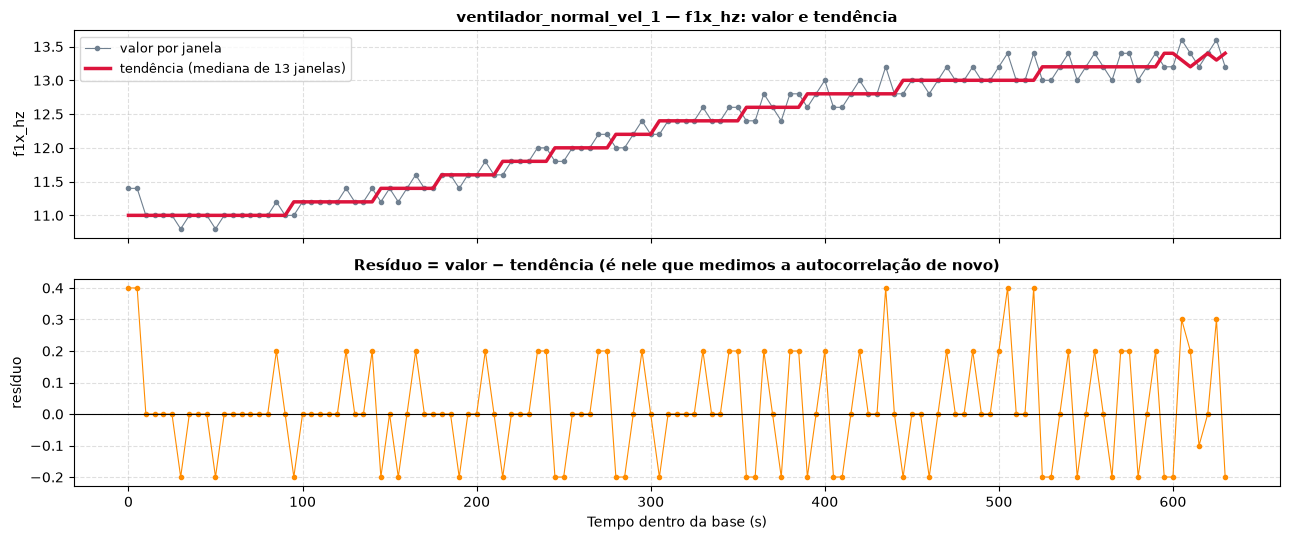

In [30]:
residuos, tendencias = remover_tendencia(features, COLUNAS_TODAS)
autocorrelacao_residuo = calcular_autocorrelacao_lag1(residuos, COLUNAS_TODAS)
display(comparar_autocorrelacao_com_e_sem_tendencia(autocorrelacao, autocorrelacao_residuo, features).round(2))

plotar_tendencia_e_residuo(features, residuos, tendencias, BASE_EXEMPLO_TENDENCIA, FEATURE_EXEMPLO_TENDENCIA)

### Conclusões do Passo 7 (dados novos)

**Autocorrelação original (7.1):**
* **Vel 1 e Vel 2:** a autocorrelação é **positiva e alta**: mediana de 0,16 a 0,63, e o percentil 90 chega a 0,85 no papel Vel 2. Uma base de cerca de 125 janelas "vale" de **29 a 92 janelas independentes**.
* **Vel 3:** a autocorrelação fica perto de zero ou negativa (de −0,13 a 0,05).

**Ciclo lento (7.2 e 7.2.1): é a oscilação, e ela acompanha a rotação.**
* O período do ciclo é de cerca de **18 a 19 s na Vel 1**, **12 s na Vel 2** e **9,5 a 10 s na Vel 3**.
* Multiplicando o período pela rotação, **um ciclo dura de 216 a 236 voltas da hélice em todas as 12 bases**. O normal Vel 1 dá 111, que é a metade: ali o pico escolhido foi o de meio ciclo, e o gráfico mostra também o pico de cerca de 18 s.
* **Conclusão:** o mecanismo da oscilação é movido pelo mesmo motor da hélice. **O ciclo é mais lento na Vel 1 e mais rápido na Vel 3.**
* Os **12 s** que o colega cronometrou batem com a **Vel 2**. Vale confirmar com ele em qual velocidade mediu, e cronometrar também as Vel 1 e 3.
* **Consequência para o tamanho da janela (Notebook 03b):** não existe uma janela única que cubra um ciclo inteiro em todas as velocidades. **12 s** cobre o ciclo da Vel 2, mas só cerca de 2/3 do ciclo da Vel 1.

**Tendência ou ciclo? (7.3)**
* Depois de tirar a tendência (mediana de 13 janelas), a autocorrelação de **todas** as bases fica **negativa**: de −0,05 a −0,44.
* Ou seja, **a dependência positiva das Vel 1 e 2 vinha do aquecimento**, e não de as janelas serem cópias umas das outras no curto prazo.
* O que sobra, negativo, é o **ciclo da oscilação**: uma janela no lado "forte" do ciclo tende a ser seguida por uma no lado "fraco".
* **Cuidado:** tirar uma mediana móvel já puxa a autocorrelação um pouco para baixo. Num ruído sem nenhuma dependência, esse efeito dá cerca de **−0,07** (simulação: 2.000 séries de 127 pontos). Valores até cerca de −0,15 podem ser só esse efeito. Os valores de **−0,3 a −0,44** (normal Vel 2 e 3, porca Vel 2 e 3) são o ciclo de verdade.

**O que isso muda:**
1. Os **p-valores** dos Passos 5 e 6 são otimistas nas Vel 1 e 2 e devem ser lidos como guia.
2. **O maior risco é o aquecimento**, e não a dependência de janela para janela. O começo e o fim de cada gravação são sistematicamente diferentes nas Vel 1 e 2. No Notebook 05, os blocos de teste (e o teste trancado) **não podem ficar todos no fim da gravação**. Se ficarem, o teste mede "motor quente" e o treino aprende "motor frio".

## Passo 8 — Transformação logarítmica

**O que buscamos:** descobrir se trocar cada valor pelo seu **logaritmo natural** deixa as features **mais próximas da normal**.

**Por que o log pode ajudar.** Features como desvio padrão, pico e amplitudes da FFT são sempre positivas e costumam ter **cauda comprida para a direita**: a maioria das janelas tem valores parecidos e algumas poucas têm valores bem maiores. O log **comprime os valores grandes** e **estica os pequenos**, deixando essa distribuição mais simétrica. É muito comum em vibração, porque efeitos de falha costumam ser **multiplicativos** (a vibração dobra) e o log transforma multiplicação em soma.

**O que o código faz:**

1. Separa as features que **aceitam log** (todas as janelas maiores que zero) das que não aceitam.
2. Aplica `np.log` nas que aceitam e **refaz os mesmos testes** (Shapiro-Wilk com BH e assimetria).
3. Compara **antes e depois**, nas **mesmas features**, para a comparação ser justa.

**Atenção a dois pontos:**

* O log **muda a escala**: depois dele, "diferença" passa a significar "razão". Isso é bom para K-Means (distância mais justa entre features de tamanhos diferentes), mas os valores deixam de estar em m/s².
* O log **não tem parâmetro para aprender**, então não causa vazamento de dados. Mas, ao usar o modelo em dados novos, o mesmo log precisa ser aplicado.

In [31]:
def separar_features_para_log(features, colunas):
    """Divide as colunas em: estritamente positivas (aceitam log) e as demais (têm zero ou valor negativo)."""
    positivas = [c for c in colunas if (features[c] > 0).all()]
    demais = [c for c in colunas if c not in positivas]
    return positivas, demais


def aplicar_log(features, colunas):
    """Devolve uma cópia da tabela com o logaritmo natural nas colunas dadas."""
    nova = features.copy()
    nova[colunas] = np.log(nova[colunas])
    return nova

In [32]:
COLUNAS_COM_LOG, COLUNAS_SEM_LOG = separar_features_para_log(features, COLUNAS_TODAS)
print(f"Recebem log: {len(COLUNAS_COM_LOG)} features (todas as janelas estritamente positivas).")
print(f"Não recebem log: {len(COLUNAS_SEM_LOG)} features -> {COLUNAS_SEM_LOG}")

features_log = aplicar_log(features, COLUNAS_COM_LOG)
resultado_log = testar_normalidade(features_log, COLUNAS_COM_LOG)
resultado_original_comparavel = resultado_original[resultado_original["feature"].isin(COLUNAS_COM_LOG)]

Recebem log: 106 features (todas as janelas estritamente positivas).
Não recebem log: 3 features -> ['kurt_x', 'kurt_y', 'kurt_z']


### 8.1 — Antes e depois do log, em números

**O que buscamos:** saber se o log **aproximou as features da normal**, olhando o mesmo teste (Shapiro-Wilk com correção BH) e a mesma assimetria nas **mesmas features**, antes e depois.

* **% normais (q BH):** sobe se o log ajudou.
* **mediana |assimetria|:** cai se o log reduziu a "cauda comprida".

In [33]:
def comparar_antes_e_depois(resultado_antes, resultado_depois, rotulo_depois="depois do log"):
    """Tabela lado a lado (por grupo) do resumo antes e depois da transformação."""
    antes = resumir_normalidade(resultado_antes)[["% normais (q BH)", "% tortas (|assim.| > limite)", "mediana |assimetria|"]]
    depois = resumir_normalidade(resultado_depois)[["% normais (q BH)", "% tortas (|assim.| > limite)", "mediana |assimetria|"]]
    return pd.concat({"antes": antes, rotulo_depois: depois}, axis=1).swaplevel(axis=1).sort_index(axis=1)


def comparar_por_tipo(resultado_antes, resultado_depois, rotulo_depois="depois do log"):
    """Resumo antes e depois, juntando todos os grupos, separado por tipo de feature."""
    linhas = {}
    for nome, resultado in (("antes", resultado_antes), (rotulo_depois, resultado_depois)):
        validos = resultado[resultado["p_bruto"].notna()]
        por_tipo = validos.groupby("tipo").apply(lambda g: pd.Series({
            "% normais (q BH)": 100 * (~g["nao_normal_bh"]).mean(),
            "% tortas": 100 * g["torta"].mean(),
            "mediana |assimetria|": g["assimetria"].abs().median(),
            "W mediano": g["W"].median(),
        }), include_groups=False)
        linhas[nome] = por_tipo
    return pd.concat(linhas, axis=1).swaplevel(axis=1).sort_index(axis=1)

In [34]:
display(comparar_antes_e_depois(resultado_original_comparavel, resultado_log).round(1))
print("Resumo por tipo de feature (todos os grupos juntos):")
display(comparar_por_tipo(resultado_original_comparavel, resultado_log).round(2))

% normais (q BH)                \
                                        antes depois do log   
condicao          velocidade                                  
fita_1g           1                       7.5          27.4   
                  2                       2.8           3.8   
                  3                       4.7          36.8   
papel             1                       4.7          26.4   
                  2                       0.9          13.2   
                  3                      10.4          40.6   
porca_frouxa      1                      14.2          34.0   
                  2                       6.6          15.1   
                  3                      20.8          45.3   
ventilador_normal 1                      15.1          26.4   
                  2                      14.2          23.6   
                  3                      23.6          28.3   

                             % tortas (|assim.| > limite)                \
                                                    antes depois do log   
condicao          velocidade                                              
fita_1g           1                                  38.7           6.6   
                  2                                  50.0          50.0   
                  3                                  59.4          29.2   
papel             1                                  54.7           6.6   
                  2                                  53.8          16.0   
                  3                                  40.6          20.8   
porca_frouxa      1                                  22.6           2.8   
                  2                                  31.1          18.9   
                  3                                  28.3           8.5   
ventilador_normal 1                                  32.1          12.3   
                  2                                  29.2          29.2   
                  3                                  24.5          17.0   

                             mediana |assimetria|                
                                            antes depois do log  
condicao          velocidade                                     
fita_1g           1                           0.8           0.3  
                  2                           1.0           1.0  
                  3                           1.2           0.5  
papel             1                           1.1           0.3  
                  2                           1.1           0.5  
                  3                           0.8           0.5  
porca_frouxa      1                           0.7           0.3  
                  2                           0.6           0.5  
                  3                           0.7           0.3  
ventilador_normal 1                           0.7           0.4  
                  2                           0.6           0.5  
                  3                           0.5           0.5

Resumo por tipo de feature (todos os grupos juntos):


% normais (q BH)               % tortas               W mediano  \
                   antes depois do log    antes depois do log     antes   
tipo                                                                      
FFT                 9.54         27.87    41.76         15.83      0.92   
rotação            12.50         17.50    22.50         39.17      0.95   
tempo              20.83         25.00    20.83         18.06      0.95   

                      mediana |assimetria|                
        depois do log                antes depois do log  
tipo                                                      
FFT              0.96                 0.85          0.44  
rotação          0.93                 0.56          0.74  
tempo            0.96                 0.48          0.37

### 8.2 — Cada feature, antes e depois

**O que buscamos:** ver o efeito do log **feature por feature**, em vez de só a média.

Cada ponto é uma feature num grupo. O eixo **x** é o W antes do log e o eixo **y** é o W depois.

* **Ponto acima da diagonal:** o log deixou a feature **mais normal**.
* **Ponto abaixo da diagonal:** o log **piorou**.
* **Ponto sobre a diagonal:** não mudou.

In [35]:
def plotar_w_antes_e_depois(resultado_antes, resultado_depois, titulo):
    """Dispersão do W antes (x) e depois (y) do log, um ponto por feature e grupo."""
    chaves = ["condicao", "velocidade", "feature"]
    juntos = resultado_antes.merge(resultado_depois, on=chaves, suffixes=("_antes", "_depois"))
    juntos = juntos[juntos["W_antes"].notna() & juntos["W_depois"].notna()]
    fig, ax = plt.subplots(figsize=(7.5, 7))
    for tipo, cor in CORES_TIPO.items():
        parte = juntos[juntos["tipo_antes"] == tipo]
        ax.scatter(parte["W_antes"], parte["W_depois"], s=14, alpha=0.5, color=cor, label=tipo)
    limites = [min(juntos["W_antes"].min(), juntos["W_depois"].min()) - 0.01, 1.005]
    ax.plot(limites, limites, color="black", linewidth=1)
    ax.set_xlim(limites)
    ax.set_ylim(limites)
    ax.set_xlabel("W antes do log")
    ax.set_ylabel("W depois do log")
    ax.legend(title="tipo de feature")
    melhoraram = 100 * (juntos["W_depois"] > juntos["W_antes"]).mean()
    ax.set_title(f"{titulo}\n{melhoraram:.0f}% dos pontos ficaram acima da diagonal", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

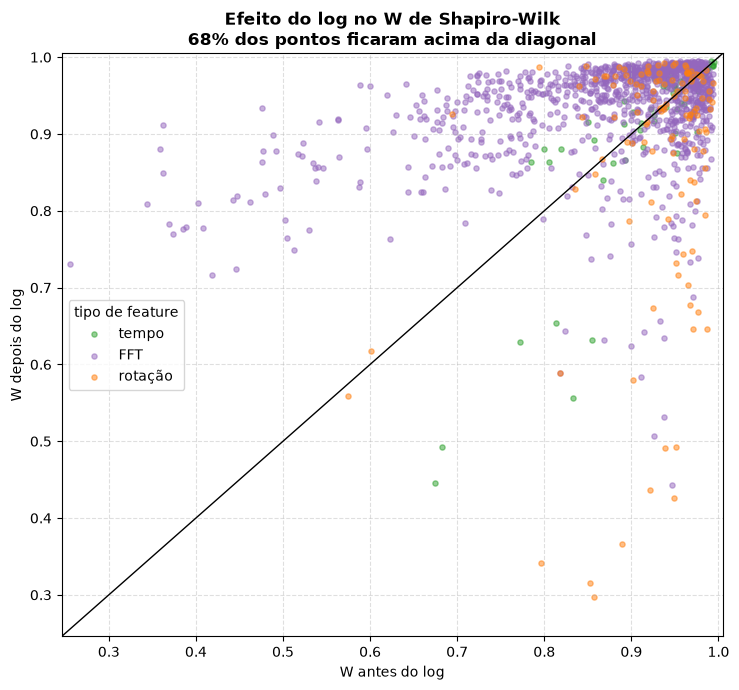

In [36]:
plotar_w_antes_e_depois(resultado_original_comparavel, resultado_log, "Efeito do log no W de Shapiro-Wilk")

### 8.3 — Histograma e QQ-plot, antes e depois

**O que buscamos:** ver com os próprios olhos o que o log fez nas features de exemplo. Para cada feature, **à esquerda** o formato original e **à direita** o formato depois do log, sempre com a curva normal por cima e o QQ-plot ao lado.

Se os pontos do QQ-plot ficam mais perto da reta depois do log, ele ajudou.

In [37]:
def plotar_antes_e_depois_do_log(features, features_log, condicao, velocidade, colunas_exemplo):
    """Por feature, de um grupo: histograma e QQ-plot antes (esquerda) e depois do log (direita)."""
    fig, axs = plt.subplots(len(colunas_exemplo), 4, figsize=(18, 3.3 * len(colunas_exemplo)), squeeze=False)
    for i, coluna in enumerate(colunas_exemplo):
        for deslocamento, tabela, rotulo in ((0, features, "antes"), (2, features_log, "depois do log")):
            valores = selecionar_janelas(tabela, [condicao], velocidade)[coluna].to_numpy()
            ax_hist, ax_qq = axs[i, deslocamento], axs[i, deslocamento + 1]
            ax_hist.hist(valores, bins=15, density=True, color="slategray", alpha=0.6)
            eixo_x = np.linspace(valores.min(), valores.max(), 200)
            ax_hist.plot(eixo_x, norm.pdf(eixo_x, valores.mean(), valores.std(ddof=1)), color="black", linewidth=1.5)
            p_valor = shapiro(valores)[1]
            ax_hist.set_title(f"{coluna} — {rotulo}\nShapiro p = {p_valor:.3g}; assimetria = {skew(valores, bias=False):.2f}", fontsize=9, fontweight="bold")
            padronizados = np.sort((valores - valores.mean()) / valores.std(ddof=1))
            teoricos = norm.ppf((np.arange(1, len(valores) + 1) - 0.5) / len(valores))
            ax_qq.scatter(teoricos, padronizados, s=12, color="slategray", alpha=0.8)
            ax_qq.plot([-3.5, 3.5], [-3.5, 3.5], color="black", linewidth=1)
            ax_qq.set_title("QQ-plot", fontsize=9, fontweight="bold")
    fig.suptitle(f"{condicao} — Vel {velocidade}", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

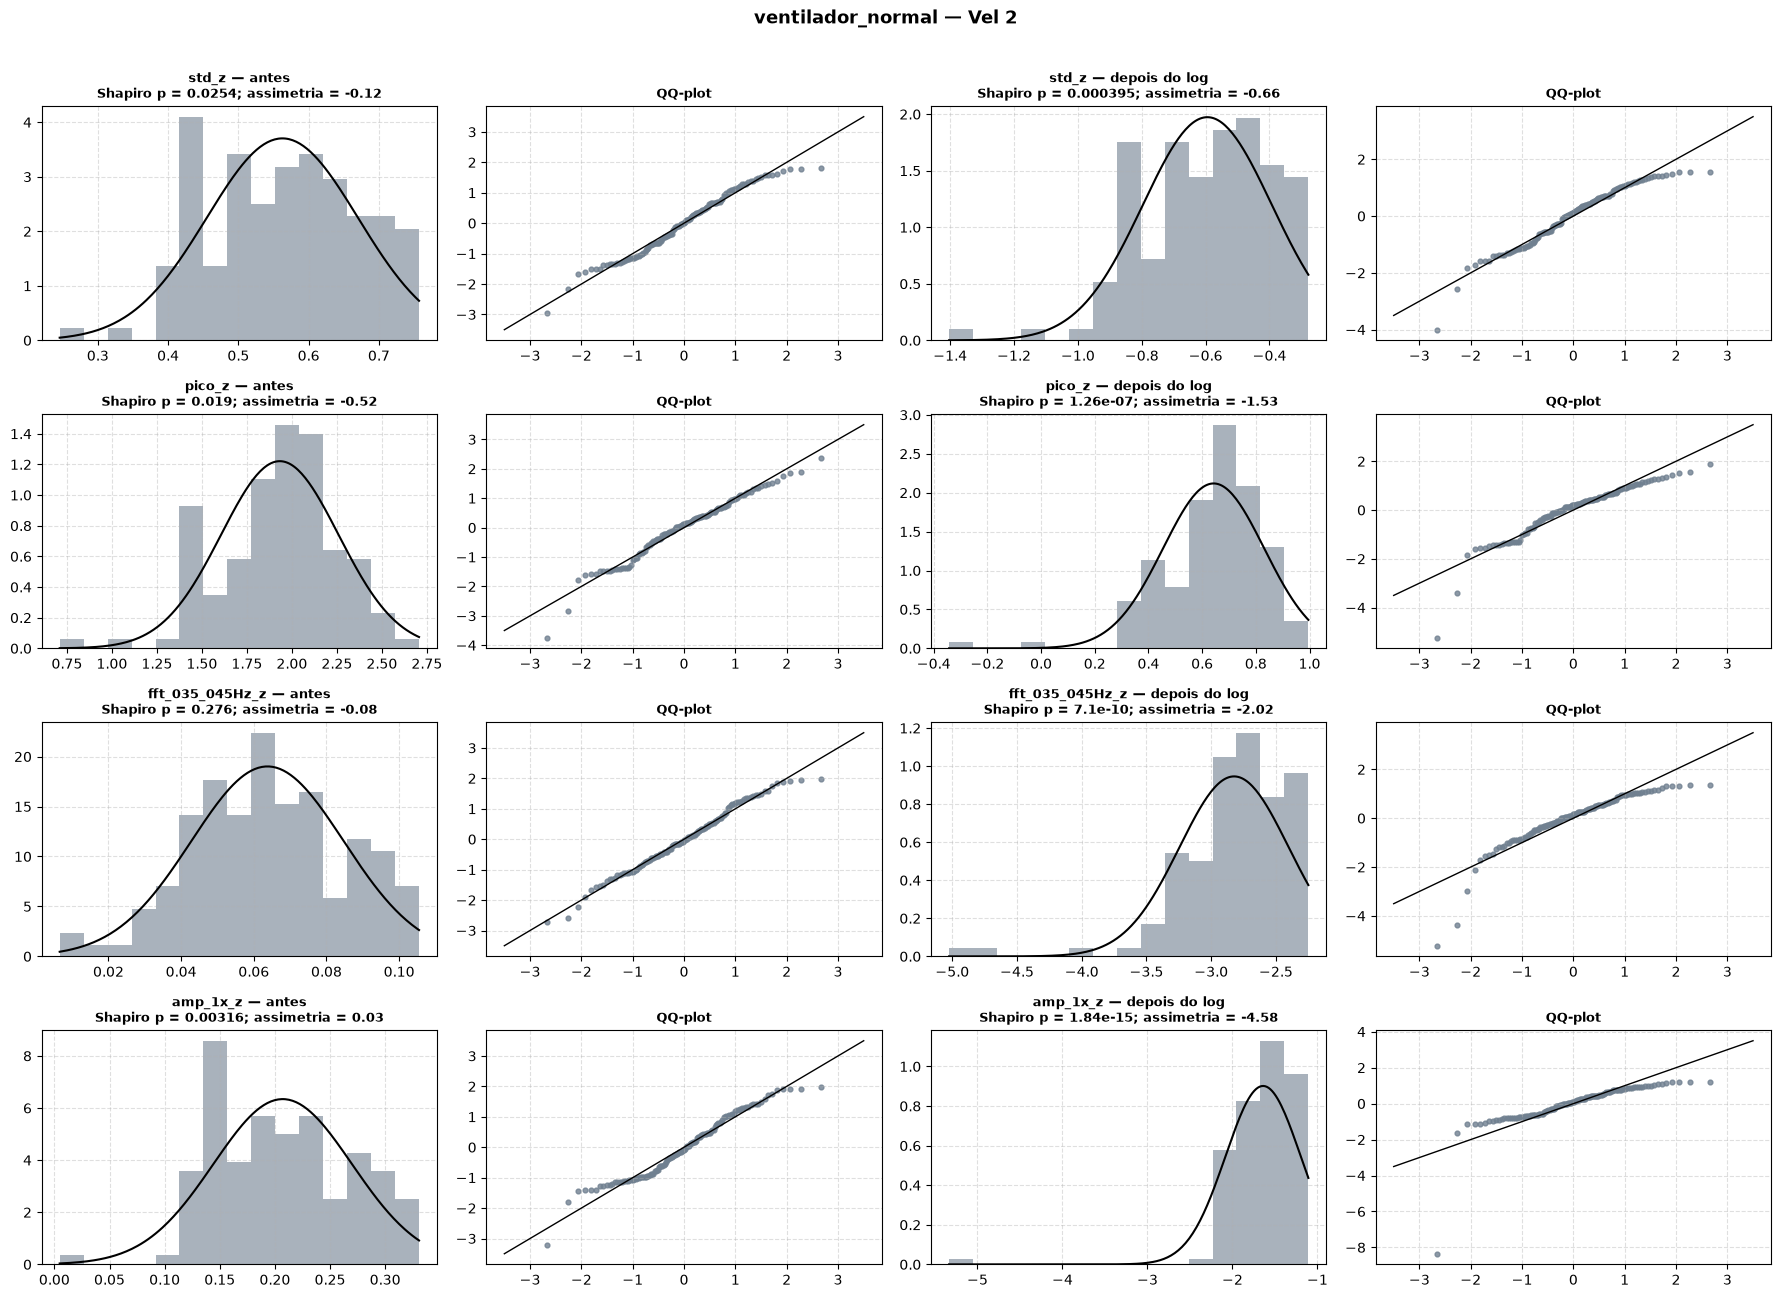

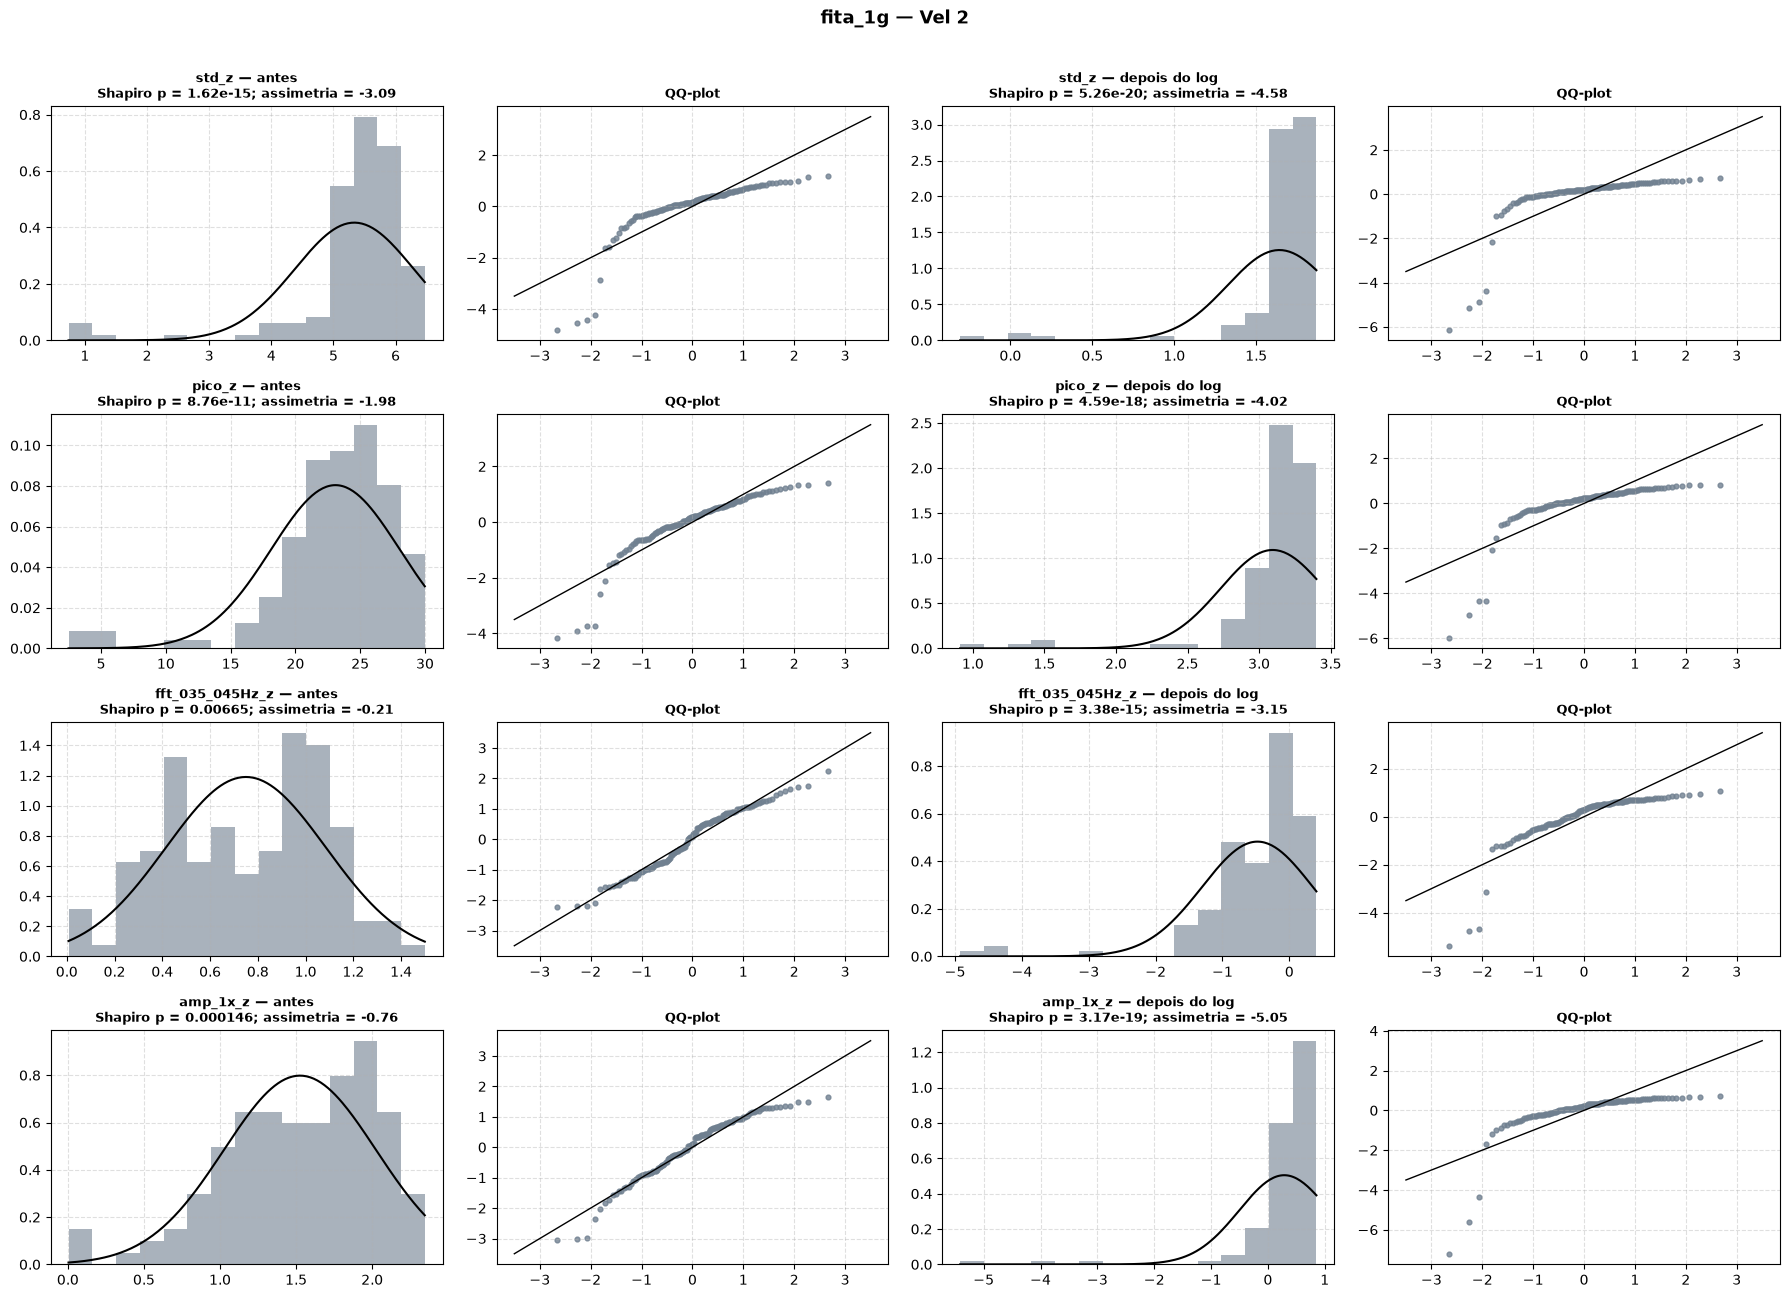

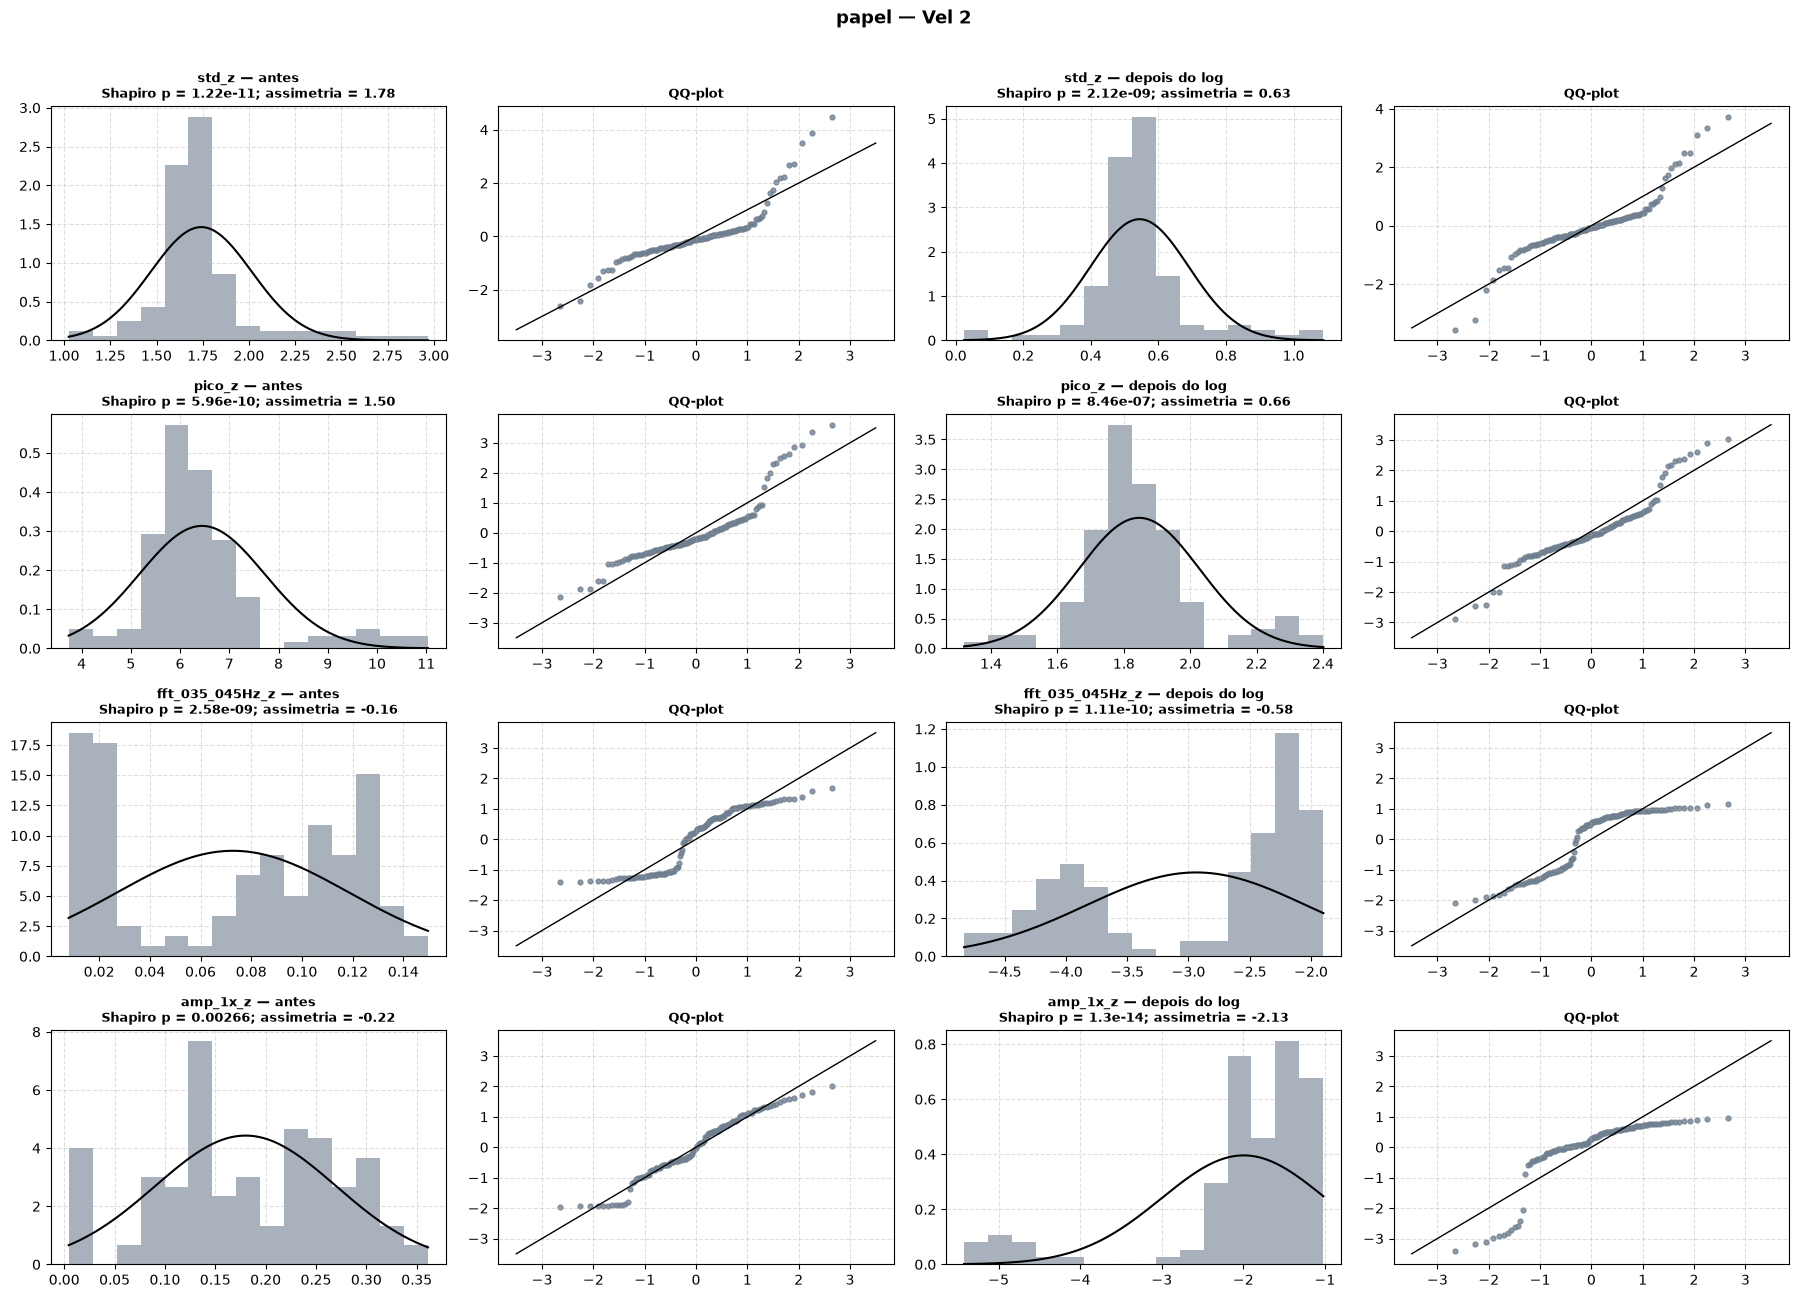

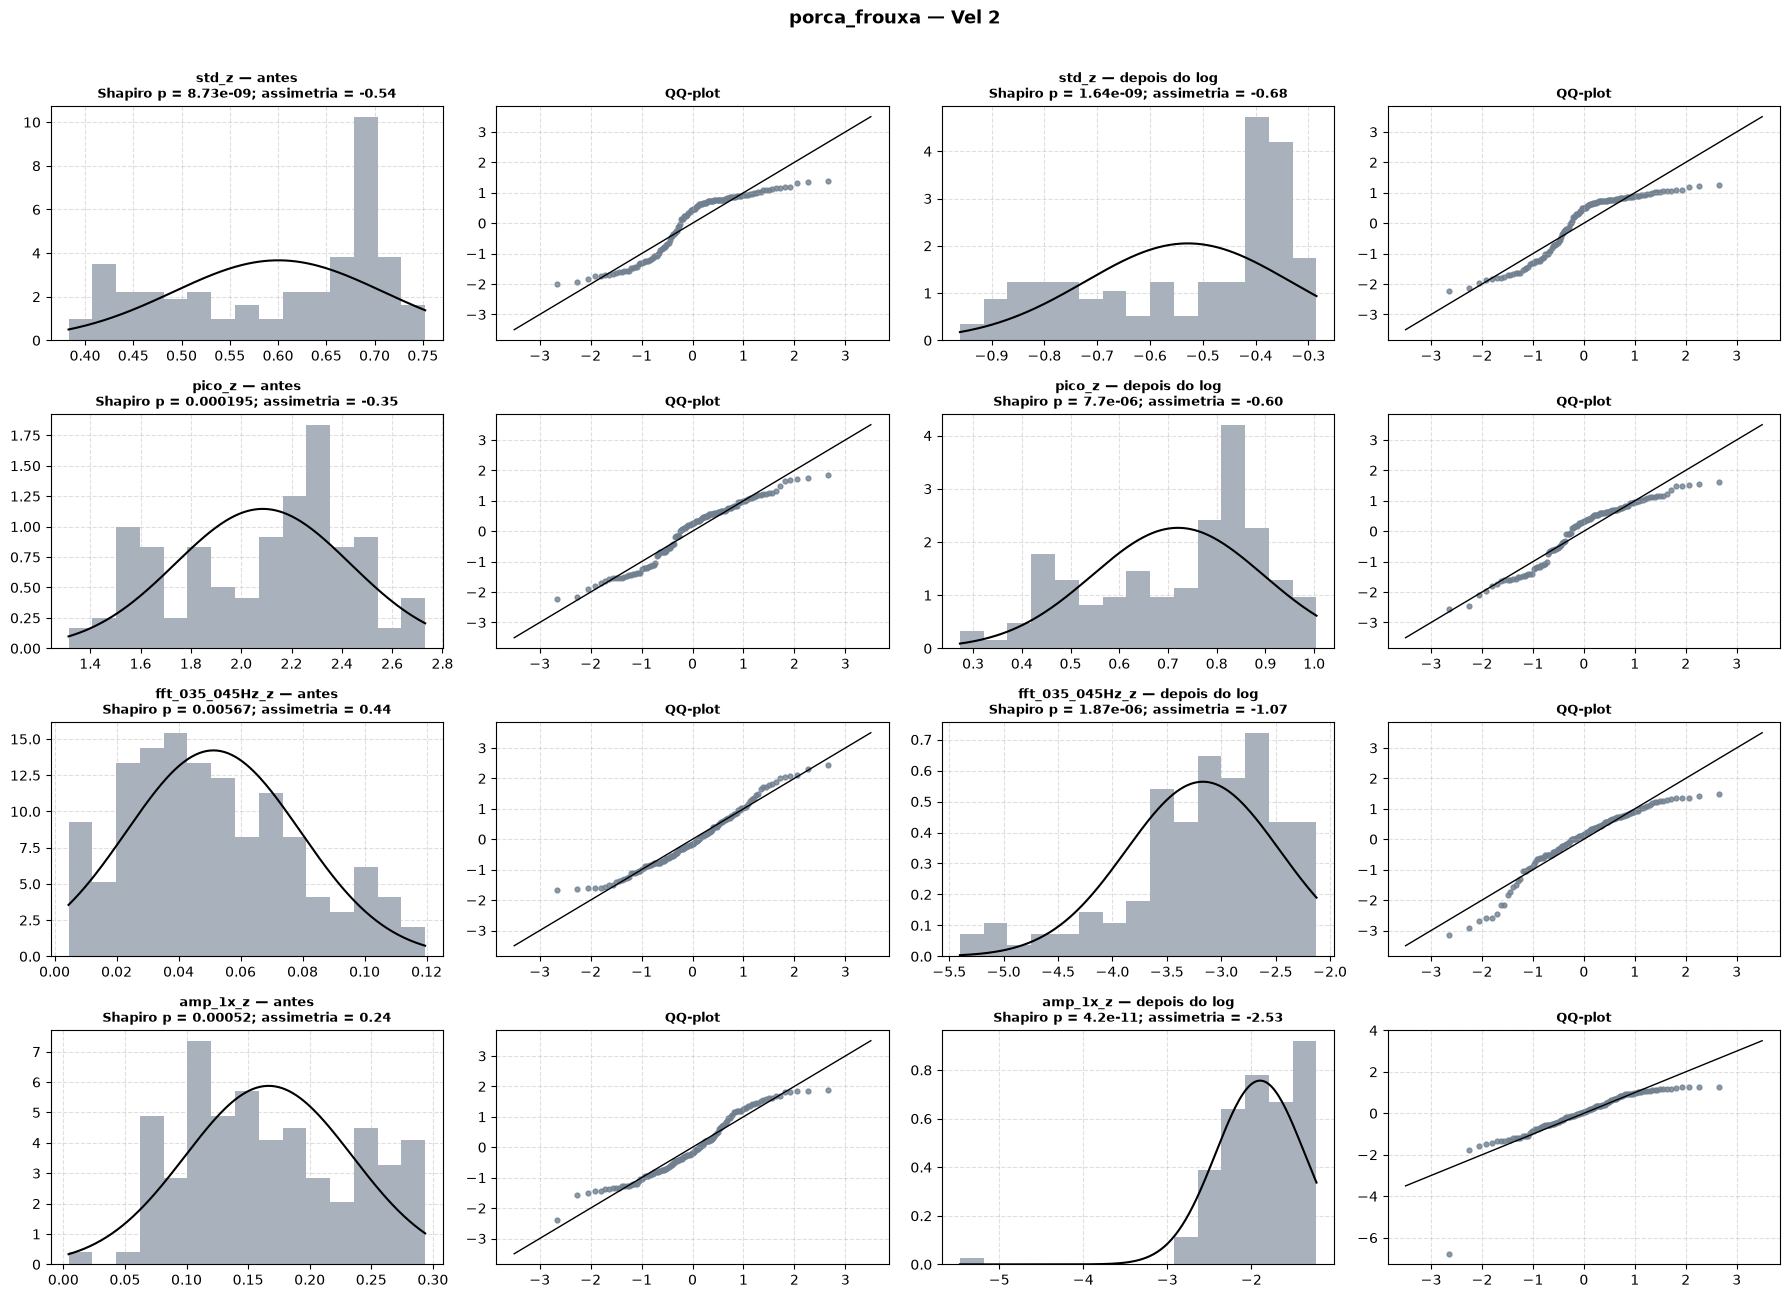

In [38]:
EXEMPLOS_COM_LOG = [c for c in FEATURES_EXEMPLO if c in COLUNAS_COM_LOG]

for condicao in CONDICOES_REFERENCIA + condicoes_comparadas:
    plotar_antes_e_depois_do_log(features, features_log, condicao, VELOCIDADE_EXEMPLO, EXEMPLOS_COM_LOG)

### Conclusões do Passo 8 (dados novos)

**Por tipo, todos os grupos juntos:**

| Tipo | % normais (antes → depois) | % tortas (antes → depois) | mediana \|assimetria\| (antes → depois) |
| --- | --- | --- | --- |
| FFT | 9,5 → **27,9** | 41,8 → **15,8** | 0,85 → **0,44** |
| Tempo (sem curtose) | 20,8 → 25,0 | 20,8 → 18,1 | 0,48 → 0,37 |
| Rotação | 12,5 → 17,5 | 22,5 → **39,2** | 0,56 → **0,74** |

* **FFT: o log ajuda muito**, de novo, como nos dados antigos. As FFT têm cauda comprida à direita (alguns picos muito altos), e o log espreme essa cauda.
* **Tempo: ajuda pouco.**
* **Rotação (`amp_kx` e `f1x_hz`): o log piora a assimetria.** O `f1x_hz` varia numa faixa estreita, e o log quase não o muda. As amplitudes harmônicas não têm cauda longa à direita, então o log cria cauda à esquerda.
* **Onde o log não ajudou:** **fita Vel 2** (50% tortas antes e depois) e **normal Vel 2** (29,2% e 29,2%). Na fita Vel 2 a cauda é **para a esquerda** (o trecho de subida do 6.3), e o log **aumenta** cauda à esquerda em vez de corrigi-la.
* **Leitura:** o log resolve **cauda longa à direita**. Ele não resolve o que vem do aquecimento ou da partida, que é uma mudança no tempo, não uma questão de formato.

## Passo 9 — Features que não aceitam log: a curtose

**O que buscamos:** a curtose (`kurt_x`, `kurt_y`, `kurt_z`) pode ser **negativa**, e o log não existe para valores negativos ou zero. Testamos uma alternativa que aceita qualquer número: a transformação **Yeo-Johnson**.

**Como funciona:** ela escolhe, para cada conjunto de dados, o **melhor "grau de esticamento"** (o parâmetro λ) para deixar a distribuição o mais simétrica possível. É uma família de transformações, e o log é um caso particular.

**Cuidado importante:** o λ é **aprendido dos dados**. Aqui ele é ajustado dentro de cada grupo (condição e velocidade) **só para comparar o formato**, e isso **não pode ser usado como pré-processamento de modelo**: num modelo, o λ deve ser ajustado só no conjunto de treino, e aplicado igual no teste (senão há vazamento de dados). Cada grupo tem um λ diferente, então os valores transformados de grupos diferentes não são comparáveis entre si.

In [39]:
def transformar_com_yeo_johnson_por_grupo(features, colunas):
    """Yeo-Johnson ajustado separadamente em cada grupo (condição x velocidade). Só para comparação descritiva."""
    nova = features.copy()
    for _, indices in features.groupby(["condicao", "velocidade"]).groups.items():
        for coluna in colunas:
            nova.loc[indices, coluna] = yeojohnson(features.loc[indices, coluna].to_numpy())[0]
    return nova

In [40]:
features_yj = transformar_com_yeo_johnson_por_grupo(features, COLUNAS_SEM_LOG)
resultado_yj = testar_normalidade(features_yj, COLUNAS_SEM_LOG)
resultado_sem_log_original = resultado_original[resultado_original["feature"].isin(COLUNAS_SEM_LOG)]

print("Features sem log: antes e depois do Yeo-Johnson (por tipo, todos os grupos juntos)")
display(comparar_por_tipo(resultado_sem_log_original, resultado_yj, "depois do Yeo-Johnson").round(2))

Features sem log: antes e depois do Yeo-Johnson (por tipo, todos os grupos juntos)


% normais (q BH)                       % tortas                        \
                 antes depois do Yeo-Johnson    antes depois do Yeo-Johnson   
tipo                                                                          
tempo            13.89                 47.22    30.56                   0.0   

      W mediano                       mediana |assimetria|  \
          antes depois do Yeo-Johnson                antes   
tipo                                                         
tempo      0.95                  0.98                 0.64   

                             
      depois do Yeo-Johnson  
tipo                         
tempo                  0.04

### Conclusões do Passo 9 (dados novos)

* **A curtose ficou mais torta nos dados novos:** mediana de |assimetria| de **0,64** (nos dados antigos era 0,34), e só 13,9% dos grupos parecem normais.
* **O Yeo-Johnson resolve o formato:** as normais sobem para **47,2%**, as tortas caem para **0%** e a assimetria cai para 0,04.
* **Mesmo assim, a decisão continua sendo não transformar a curtose:**
  1. O Yeo-Johnson **aprende um parâmetro (λ) com os dados**. Ajustado em todas as janelas, como aqui, ele vê o teste e gera vazamento. Para usá-lo, ele teria de entrar **dentro do Pipeline**, ajustado só no treino, como o scaler.
  2. O ganho em formato não garante ganho no modelo. O que importa para o K-Means e para o classificador é a escala e os extremos, e a curtose tem poucos extremos.
* **Opção para o Notebook 05:** testar um `PowerTransformer` (Yeo-Johnson) **dentro do Pipeline**, só nas 3 curtoses, como variação. Se não melhorar a acurácia balanceada mais do que a regra de empate, fica a versão mais simples.

## Resumo e decisões para o Notebook 04

**O que buscamos:** uma tabela única, por tipo de feature, com o estado das distribuições **antes** e **depois do log**, e as decisões que levamos para o K-Means.

Como ler a tabela: **% normais** deve subir e **mediana |assimetria|** deve cair se o log ajudar. As duas medidas têm de apontar para o mesmo lado para a conclusão ser firme.

In [41]:
def montar_tabela_de_decisoes(resultado_antes, resultado_depois):
    """Resumo final: por tipo de feature, como estão as distribuições antes e depois do log."""
    tabela = comparar_por_tipo(resultado_antes, resultado_depois)
    return tabela[[("% normais (q BH)", "antes"), ("% normais (q BH)", "depois do log"),
                   ("mediana |assimetria|", "antes"), ("mediana |assimetria|", "depois do log")]]

In [42]:
display(montar_tabela_de_decisoes(resultado_original_comparavel, resultado_log).round(2))

% normais (q BH)               mediana |assimetria|              
                   antes depois do log                antes depois do log
tipo                                                                     
FFT                 9.54         27.87                 0.85          0.44
rotação            12.50         17.50                 0.56          0.74
tempo              20.83         25.00                 0.48          0.37

### Decisões para o Notebook 04 (dados novos)

**Respostas diretas às perguntas do início:**

1. **As features são normais?** Não. Só cerca de **11%** passam no teste (16% a 23% no normal, e de 1% a 20% nas falhas).
2. **O desvio é grave?** Para a maioria, não: 666 de 1.308 testes rejeitam a normalidade sem a feature ser torta. As **FFT** são o tipo mais torto (42% tortas), com cauda à direita.
3. **O log ajuda?** **Nas FFT, muito** (tortas de 42% para 16%). Em tempo ajuda pouco. **Em rotação, piora** (tortas de 22% para 39%).

| Decisão | Por quê |
| --- | --- |
| **Não exigir normalidade** | O K-Means e os classificadores usam distância ou cortes. O que pesa é a escala e os extremos, não o sino. |
| **Log em todas as features menos as curtoses** (decisão vigente) | Mantida pela simplicidade e porque o log não aprende nada dos dados. Nos dados novos o log **piorou a assimetria das features de rotação**: fica anotado como variação a testar no Notebook 05 (log só em FFT, tempo e amplitudes). |
| **Curtose sem transformação** | O Yeo-Johnson exigiria ajustar λ no treino. Pode ser testado dentro do Pipeline no Notebook 05. |
| **Ordem: log primeiro, scaler depois** | O log não tem parâmetro. O scaler tem, e deve ser ajustado só com os dados do treino. |
| **Manter todas as janelas** | As atípicas são a partida do motor e a subida da vibração da fita Vel 2. É comportamento real, não falha de leitura. |
| **Tratar os p-valores como guia** | As janelas não são independentes nas Vel 1 e 2 (aquecimento). |

**Cuidados para o K-Means (Notebook 04) e a classificação (Notebook 05):**

* **Aquecimento:** nas Vel 1 e 2, o começo e o fim de cada gravação são diferentes. No K-Means, **pinte as janelas pelo tempo dentro da base**: se um cluster juntar "todo o começo" e outro "todo o fim", o modelo separou temperatura, e não condição. No Notebook 05, espalhe os blocos de teste e o trancado ao longo da gravação.
* **Ciclo da oscilação:** dura cerca de **225 voltas da hélice**, ou seja, cerca de 18 s na Vel 1, 12 s na Vel 2 e 10 s na Vel 3. Com janelas de 5 s, cada janela pega uma parte diferente do ciclo. Isso é variação dentro da classe, e não falha.
* **Fita Vel 2:** os primeiros cerca de 250 s são um trecho de transição (vibração ainda crescendo). Se o modelo errar janelas da fita Vel 2, olhe primeiro esse trecho.

**Perguntas para o grupo:**

1. **Em qual velocidade foram cronometrados os 12 s do ciclo?** Os dados indicam cerca de 18 s na Vel 1, 12 s na Vel 2 e 10 s na Vel 3. Vale cronometrar as três.
2. **A fita Vel 2 foi gravada com o motor frio, como as outras?** A vibração cresce bastante nos primeiros 4 minutos, mais do que nas outras bases.

## O que conferir antes de seguir para o Notebook 04

* [ ] **Passo 2:** as bases e o número de janelas por condição e velocidade fazem sentido.
* [ ] **Passo 5:** você entendeu a diferença entre "p bruto" e "q BH", e qual dos dois é o critério principal.
* [ ] **Passo 6:** você viu, nos histogramas e QQ-plots, **como** as features se afastam da normal (cauda comprida, picos, dois grupos).
* [ ] **Passo 7:** a autocorrelação entre janelas foi lida, e os p-valores são tratados como guia.
* [ ] **Passo 7.2.1 e 7.3:** você viu que o ciclo da oscilação acompanha a rotação e que a dependência entre janelas vem principalmente do aquecimento.
* [ ] **Passo 8:** o resultado do log (quantas features melhoraram) está anotado.
* [ ] **Resumo:** as decisões para o K-Means estão anotadas.

**Próximo passo:** Notebook 04, **K-Means com scaler local**, usando as decisões do resumo acima.